### Setup

In [12]:
import copy, math, os, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import urllib.request
from scipy.optimize import linear_sum_assignment
import os

torch.manual_seed(5561)
dev = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", dev)


def show_grid(x, title="", rows=8):
    # x: (n, 1, 28, 28) in [-1, 1]
    g = torchvision.utils.make_grid(x[:rows * rows].detach().float().cpu(), nrow=rows,
                                    padding=2, pad_value=1)
    plt.figure(figsize=(5, 5)); plt.imshow(g[0], cmap="gray", vmin=-1, vmax=1)
    plt.title(title); plt.axis("off"); plt.show()


if not Path("mnist_classifier.pt").is_file():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/SJGuy-UMN/CSCI5561/main/mnist_classifier.pt",
        "mnist_classifier.pt",
    )
clf = torch.jit.load("mnist_classifier.pt", map_location="cpu").eval()


device: cuda


In [6]:
def show_grid_highlighted(x, clf=clf, threshold=0.99, rows=8, border_width=2, 
                          title="Generated Samples (Red Border: Conf <= 0.99)", 
                          save_path=None):
    """
    Renders an n x n grid of generated images. Samples with classifier confidence <= threshold 
    are highlighted with a red border.
    
    Parameters:
      x: Tensor in [-1, 1] of shape (N, 1, 28, 28) OR uint8 array/tensor of shape (N, 28, 28)
      clf: The loaded MNIST classifier model
      threshold: Cutoff confidence (default: 0.99)
      rows: Number of rows/cols in grid (default: 8 for 64 images)
      border_width: Thickness of the red highlight border in pixels
      save_path: Optional file path to save the figure (e.g. 'Report/Results/highlighted.png')
    """
    if isinstance(x, np.ndarray):
        x = torch.from_numpy(x)
        
    # Convert to uint8 for classifier input and [0, 1] RGB for grid visualization
    if x.dtype == torch.uint8:
        u8 = x if x.ndim == 3 else x.squeeze(1)
        rgb = (u8.float() / 255.0).unsqueeze(1).repeat(1, 3, 1, 1)
    else:
        if x.ndim == 3:
            x = x.unsqueeze(1)
        u8 = ((x[:, 0] + 1) * 127.5).round().clamp(0, 255).to(torch.uint8)
        rgb = ((x + 1.0) / 2.0).clamp(0, 1).repeat(1, 3, 1, 1)
        
    n = min(len(u8), rows * rows)
    u8 = u8[:n]
    rgb = rgb[:n].clone()
    
    # Run classifier
    with torch.no_grad():
        p = clf(u8.cpu())
    confs, digits = p.max(1)
    
    # Draw red border on samples where confidence <= threshold
    b = border_width
    for i, conf in enumerate(confs):
        if conf.item() <= threshold:
            rgb[i, 0, :b, :] = 1.0; rgb[i, 1:, :b, :] = 0.0  # Top border
            rgb[i, 0, -b:, :] = 1.0; rgb[i, 1:, -b:, :] = 0.0  # Bottom border
            rgb[i, 0, :, :b] = 1.0; rgb[i, 1:, :, :b] = 0.0  # Left border
            rgb[i, 0, :, -b:] = 1.0; rgb[i, 1:, :, -b:] = 0.0  # Right border
            
    # Build grid with dark gray padding
    grid = torchvision.utils.make_grid(rgb, nrow=rows, padding=2, pad_value=0.25)
    
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
    num_flagged = (confs <= threshold).sum().item()
    plt.title(f"{title}\n({num_flagged}/{n} samples with conf <= {threshold:.2f})", fontsize=11, pad=10)
    plt.axis("off")
    if save_path:
        plt.savefig(save_path, bbox_inches="tight", dpi=200)
    plt.show()


def show_low_confidence_samples(x, clf=clf, threshold=0.99, max_show=16, rows=4, 
                                title="Low-Confidence Failure Analysis (Conf <= 0.99)", 
                                save_path=None):
    """
    Extracts and ranks the lowest-confidence samples from the batch, showing the 
    predicted class and confidence percentage for in-depth report discussion.
    """
    if isinstance(x, np.ndarray):
        x = torch.from_numpy(x)
        
    if x.dtype == torch.uint8:
        u8 = x if x.ndim == 3 else x.squeeze(1)
    else:
        if x.ndim == 4:
            x = x[:, 0]
        u8 = ((x + 1.0) * 127.5).round().clamp(0, 255).to(torch.uint8)
        
    with torch.no_grad():
        p = clf(u8.cpu())
    confs, digits = p.max(1)
    
    low_idx = torch.where(confs <= threshold)[0]
    if len(low_idx) == 0:
        print(f"All {len(u8)} samples have confidence > {threshold:.2f}!")
        return
        
    # Sort from lowest confidence first
    sorted_sub_idx = confs[low_idx].argsort()
    selected_idx = low_idx[sorted_sub_idx][:max_show]
    
    n = len(selected_idx)
    cols = int(np.ceil(n / rows))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 1.9))
    axes = np.array(axes).reshape(-1)
    
    for ax_i, idx in enumerate(selected_idx):
        img = u8[idx].cpu().numpy()
        c = confs[idx].item()
        d = digits[idx].item()
        axes[ax_i].imshow(img, cmap="gray")
        axes[ax_i].set_title(f"Pred: {d}\nConf: {c:.1%}", color="red", fontsize=8, pad=3)
        axes[ax_i].axis("off")
        
    for ax_i in range(n, len(axes)):
        axes[ax_i].axis("off")
        
    plt.suptitle(title, fontsize=11, y=0.98)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight", dpi=200)
    plt.show()


torch.Size([60000, 1, 28, 28]) -1.0 1.0


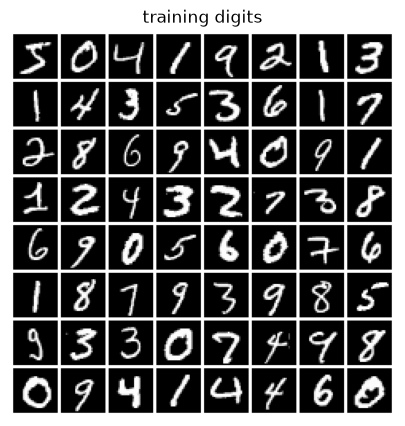

In [7]:
train = torchvision.datasets.MNIST("data", train=True, download=True)

def to_net(u8):                     # uint8 0-255  ->  float [-1, 1], shape (n, 1, 28, 28)
    return (u8.float() / 127.5 - 1).unsqueeze(1)

X = to_net(train.data)             # shared CPU copy
print(X.shape, X.min().item(), X.max().item())
show_grid(X, "training digits")
test = torchvision.datasets.MNIST("data", train=False, download=True)
xtr, xte = X, to_net(test.data)


In [8]:
def to_uint8(x):
    # [-1, 1], (n, 1, 28, 28) -> uint8 0–255, (n, 28, 28)
    return ((x[:, 0] + 1) * 127.5).round().clamp(0, 255).to(torch.uint8).cpu()

def recognition(u8):
    with torch.no_grad():
        p = clf(torch.as_tensor(u8).cpu())
    conf, digit = p.max(1)
    return (conf > 0.99).float().mean().item(), torch.bincount(digit, minlength=10), conf, digit

### 1. Two-Dimensional Flow Matching 

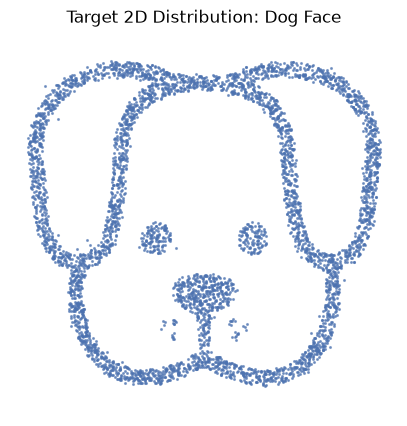

In [4]:
from PIL import Image

def sample_dog_face(batch_size, image_path="dog_face.png"):
    # 1. Load image and invert so dog = 1 (high probability), background = 0
    img = Image.open(image_path).convert("L")
    arr = 1.0 - (np.array(img, dtype=np.float32) / 255.0)
    
    # 2. Convert to probability distribution
    probs = (arr / arr.sum()).ravel()
    
    # 3. Sample pixel indices
    indices = np.random.choice(arr.size, size=batch_size, p=probs)
    y, x = np.unravel_index(indices, arr.shape)
    
    # 4. Add small jitter so points are continuous, flip y so it is upright
    pts = np.stack([
        x + np.random.uniform(-0.5, 0.5, size=batch_size),
        -y + np.random.uniform(-0.5, 0.5, size=batch_size)
    ], axis=1)
    
    # 5. Standardize to mean 0, std 1 (standard for flow matching)
    pts = (pts - pts.mean(0)) / pts.std(0)
    return torch.tensor(pts, dtype=torch.float32)

# --- Visualize your target distribution ---
target_points = sample_dog_face(5000)
plt.figure(figsize=(5, 5))
plt.scatter(target_points[:, 0], target_points[:, 1], s=1.5, alpha=0.6, color="#4C72B0")
plt.title("Target 2D Distribution: Dog Face")
plt.axis("equal")
plt.axis("off")
plt.show()



In [ ]:
def flow_matching_2D():
    class Net(nn.Module):
        def __init__(self, hidden=128):
            super().__init__()
            self.mlp = nn.Sequential(
                nn.Linear(3, hidden),
                nn.ReLU(),
                nn.Linear(hidden, hidden),
                nn.ReLU(),
                nn.Linear(hidden, hidden),
                nn.ReLU(),
                nn.Linear(hidden, 2),
            )

        def forward(self, x):
            return self.mlp(x)


    def train(net, steps=4000):
        opt = torch.optim.Adam(net.parameters(), lr=1e-3)
        for step in range(steps):
            x1 = sample_dog_face(512).to(dev)
            x0 = torch.randn_like(x1)
            t = torch.rand(len(x1), 1, device=dev)
            xt = (1 - t) * x0 + t * x1
            target = x1 - x0
            loss = ((net(torch.cat([xt, t], 1)) - target) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        return loss.item()


    @torch.no_grad()
    def sample(model, x, N=50):
        # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            x = x + model(torch.cat([x, t], 1)) / N 
        return x

    
    @torch.no_grad()
    def plot_comparison(net, n_samples=2000):
        net.eval()
        # 1. Sample true data
        true_pts = sample_dog_face(n_samples).numpy()
        
        # 2. Generate samples from pure Gaussian noise
        z0 = torch.randn(n_samples, 2, device=dev)
        gen_pts = sample(net, z0, N=50).cpu().numpy()
        
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        
        axes[0].scatter(true_pts[:, 0], true_pts[:, 1], s=2, alpha=0.5, color="#1f77b4")
        axes[0].set_title(f"True Distribution ({n_samples} points)", fontsize=13)
        axes[0].set_xlim(-3, 3); axes[0].set_ylim(-3, 3)
        axes[0].set_aspect("equal"); axes[0].grid(True, alpha=0.3)
        
        axes[1].scatter(gen_pts[:, 0], gen_pts[:, 1], s=2, alpha=0.5, color="#ff7f0e")
        axes[1].set_title(f"Generated via Flow Matching ({n_samples} points)", fontsize=13)
        axes[1].set_xlim(-3, 3); axes[1].set_ylim(-3, 3)
        axes[1].set_aspect("equal"); axes[1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()


    @torch.no_grad()
    def plot_velocity_fields(net, grid_size=25, lim=2.5):
        net.eval()
        # Create 2D coordinate grid
        x_vals = np.linspace(-lim, lim, grid_size)
        y_vals = np.linspace(-lim, lim, grid_size)
        X, Y = np.meshgrid(x_vals, y_vals)
        pts = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32, device=dev)
        
        times = [0.0, 0.5, 1.0]
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        for ax, t_val in zip(axes, times):
            t = torch.full((len(pts), 1), t_val, device=dev)
            # Predict velocity vector (u, v)
            vel = net(torch.cat([pts, t], dim=1)).cpu().numpy()
            U = vel[:, 0].reshape(grid_size, grid_size)
            V = vel[:, 1].reshape(grid_size, grid_size)
            
            # Normalize arrows slightly for clean visualization
            speed = np.sqrt(U**2 + V**2) + 1e-5
            
            ax.quiver(X, Y, U, V, speed, cmap="viridis", alpha=0.85)
            ax.set_title(f"Velocity Field at t = {t_val}", fontsize=13)
            ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
            ax.set_aspect("equal"); ax.grid(True, alpha=0.2)
            
        plt.tight_layout()
        plt.show()

    
    @torch.no_grad()
    def plot_trajectories(net, n_paths=120, steps=50):
        net.eval()
        # 1. Fixed starting noise samples at t=0
        torch.manual_seed(42)
        x = torch.randn(n_paths, 2, device=dev)
        
        # 2. Record every intermediate integration step
        traj = [x.cpu().numpy()]
        dt = 1.0 / steps
        for i in range(steps):
            t = torch.full((len(x), 1), i * dt, device=dev)
            v = net(torch.cat([x, t], dim=1))
            x = x + v * dt
            traj.append(x.cpu().numpy())
            
        traj = np.array(traj)  # shape: (steps + 1, n_paths, 2)
        
        # 3. Plot paths
        plt.figure(figsize=(7, 7))
        
        # Plot target distribution faintly in background for reference
        true_ref = sample_dog_face(1500).numpy()
        plt.scatter(true_ref[:, 0], true_ref[:, 1], s=1, color="lightgray", alpha=0.5, label="Target Dog Shape")
        
        # Plot individual trajectories
        for i in range(n_paths):
            plt.plot(traj[:, i, 0], traj[:, i, 1], color="#2b5c8f", alpha=0.35, lw=1)
            
        # Mark start points (t=0) and end points (t=1)
        plt.scatter(traj[0, :, 0], traj[0, :, 1], s=16, color="#d95f02", label="Initial Noise (t=0)", zorder=3)
        plt.scatter(traj[-1, :, 0], traj[-1, :, 1], s=16, color="#1b9e77", label="Final Generated (t=1)", zorder=4)
        
        plt.title(f"Flow Trajectories ({n_paths} samples)", fontsize=13)
        plt.xlim(-3, 3); plt.ylim(-3, 3)
        plt.gca().set_aspect("equal")
        plt.legend(loc="upper right", framealpha=0.9)
        plt.grid(True, alpha=0.25)
        plt.show()

    
    net = Net().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    final_loss = train(net, steps=4000)
    print(f"Training complete. Final loss: {final_loss:.4f}")

    plot_comparison(net)
    plot_velocity_fields(net)
    plot_trajectories(net, n_paths=120)


33,794 weights
Training complete. Final loss: 1.3736


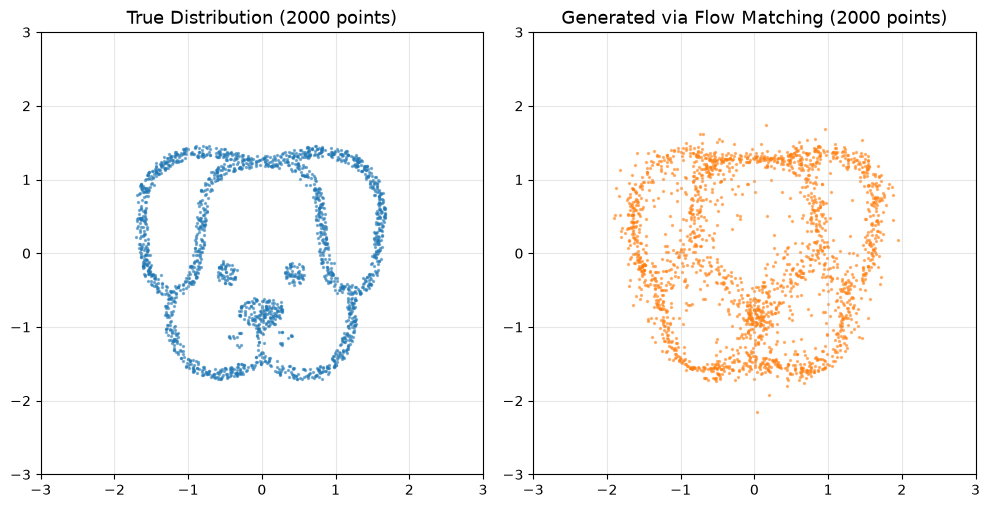

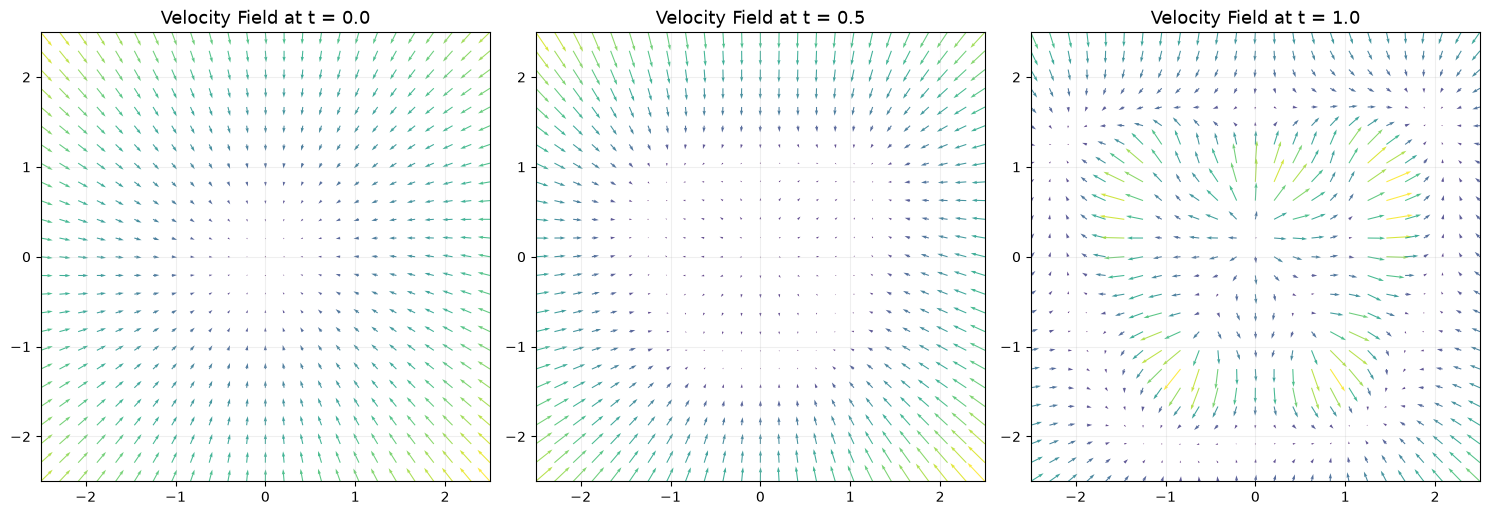

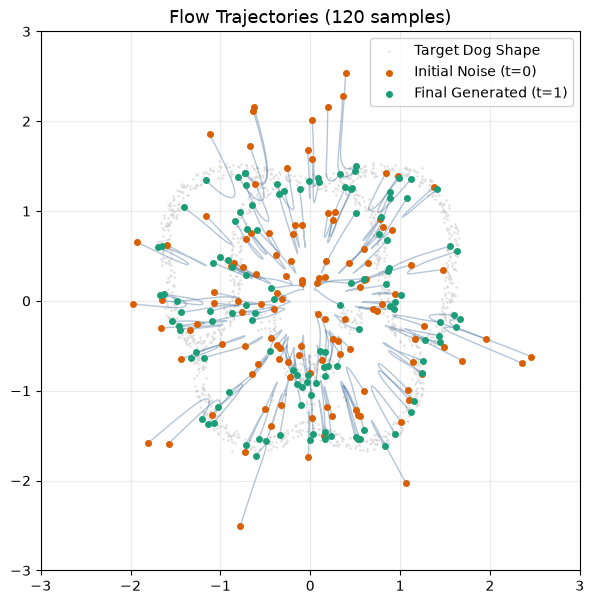

In [19]:
flow_matching_2D()

### 2. Image Model and Training Diagnostics 

In [4]:
def one_batch_overfit():
    torch.manual_seed(5561)
    X = xtr[:16].to(dev)
    show_grid(X, "16 One-Batch Training Images", rows=4)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, cout)                        # one offset per channel

        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            return F.relu(self.c2(F.relu(h)))


    class UNet(nn.Module):
        def __init__(self, width=16, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
            self.down1 = Block(1, c, tdim)                    # 28 x 28
            self.down2 = Block(c, 2 * c, tdim)                # 14 x 14
            self.mid = Block(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Block(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Block(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)

    @torch.no_grad()
    def sample(model, x, N=50):
        # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            x = x + model(x, t) / N
        return x

    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 3000, 16, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    Z = torch.randn(16, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)  # fixed noise for 16 images 


    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        if (epoch + 1) == 500:
            show_grid(sample(net, Z), "16 Early Samples", rows=4)
        if (epoch + 1) % 250 == 0:
            print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()


    net.eval()
    show_grid(sample(net, Z), "16 Late Samples", rows=4)

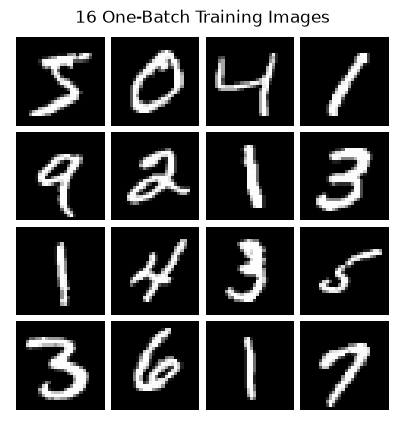

124,145 weights
epoch 250: loss 0.4271  (6 s)


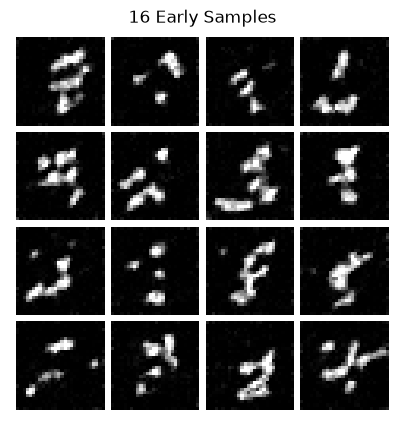

epoch 500: loss 0.3156  (12 s)
epoch 750: loss 0.2654  (19 s)
epoch 1000: loss 0.2383  (25 s)
epoch 1250: loss 0.1942  (29 s)
epoch 1500: loss 0.1731  (34 s)
epoch 1750: loss 0.1611  (38 s)
epoch 2000: loss 0.1428  (44 s)
epoch 2250: loss 0.1327  (53 s)
epoch 2500: loss 0.1208  (58 s)
epoch 2750: loss 0.1240  (62 s)
epoch 3000: loss 0.1196  (66 s)


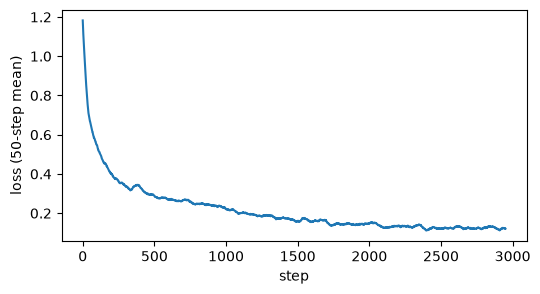

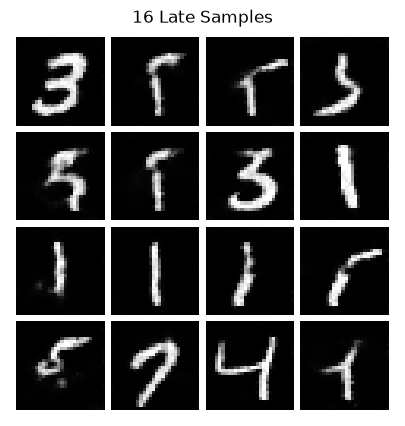

In [22]:
one_batch_overfit()

### 3. Unconditional Image Generation 

In [8]:
def baseline():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, cout)                        # one offset per channel

        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            return F.relu(self.c2(F.relu(h)))


    class UNet(nn.Module):
        def __init__(self, width=16, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
            self.down1 = Block(1, c, tdim)                    # 28 x 28
            self.down2 = Block(c, 2 * c, tdim)                # 14 x 14
            self.mid = Block(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Block(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Block(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 30, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    @torch.no_grad()
    def sample(model, x, N=50):
        # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            x = x + model(x, t) / N
        return x


    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")
    
    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


124,145 weights
epoch 1: loss 0.3293  (5 s)
epoch 2: loss 0.2748  (11 s)
epoch 3: loss 0.2488  (16 s)
epoch 4: loss 0.2356  (21 s)
epoch 5: loss 0.2298  (26 s)
epoch 6: loss 0.2233  (31 s)
epoch 7: loss 0.2201  (36 s)
epoch 8: loss 0.2166  (41 s)
epoch 9: loss 0.2156  (46 s)
epoch 10: loss 0.2128  (51 s)
epoch 11: loss 0.2098  (57 s)
epoch 12: loss 0.2083  (62 s)
epoch 13: loss 0.2076  (67 s)
epoch 14: loss 0.2079  (72 s)
epoch 15: loss 0.2045  (77 s)
epoch 16: loss 0.2031  (82 s)
epoch 17: loss 0.2019  (87 s)
epoch 18: loss 0.2045  (92 s)
epoch 19: loss 0.2096  (98 s)
epoch 20: loss 0.1999  (103 s)
epoch 21: loss 0.2000  (108 s)
epoch 22: loss 0.2004  (114 s)
epoch 23: loss 0.1979  (119 s)
epoch 24: loss 0.1972  (124 s)
epoch 25: loss 0.1985  (130 s)
epoch 26: loss 0.1994  (135 s)
epoch 27: loss 0.1992  (140 s)
epoch 28: loss 0.2002  (145 s)
epoch 29: loss 0.1964  (151 s)
epoch 30: loss 0.1982  (156 s)


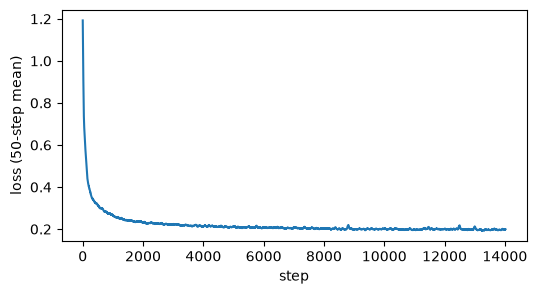

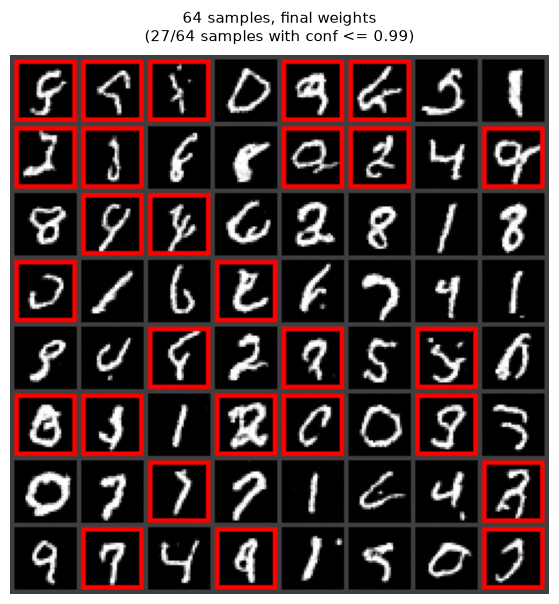

recognition score 60.1%   coverage not full
predicted-digit counts [226, 214, 175, 146, 270, 120, 185, 234, 251, 179]   (full coverage needs 140 of each)


In [9]:
baseline()

In [10]:
def two_blocks_per_level():
    out_dir = Path("flow_matching_examples/two_blocks")
    out_dir.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, cout)                        # one offset per channel

        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            return F.relu(self.c2(F.relu(h)))


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=16, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 30, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    @torch.no_grad()
    def sample(model, x, N=50):
        # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            x = x + model(x, t) / N
        return x


    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


249,553 weights
epoch 1: loss 0.3304  (8 s)
epoch 2: loss 0.2635  (17 s)
epoch 3: loss 0.2409  (26 s)
epoch 4: loss 0.2269  (34 s)
epoch 5: loss 0.2185  (42 s)
epoch 6: loss 0.2126  (51 s)
epoch 7: loss 0.2095  (60 s)
epoch 8: loss 0.2066  (68 s)
epoch 9: loss 0.2019  (77 s)
epoch 10: loss 0.2017  (85 s)
epoch 11: loss 0.1985  (94 s)
epoch 12: loss 0.1983  (103 s)
epoch 13: loss 0.1974  (112 s)
epoch 14: loss 0.1962  (120 s)
epoch 15: loss 0.1932  (129 s)
epoch 16: loss 0.1920  (137 s)
epoch 17: loss 0.1900  (146 s)
epoch 18: loss 0.1903  (155 s)
epoch 19: loss 0.1911  (163 s)
epoch 20: loss 0.1901  (172 s)
epoch 21: loss 0.1889  (181 s)
epoch 22: loss 0.1878  (190 s)
epoch 23: loss 0.1864  (198 s)
epoch 24: loss 0.1857  (206 s)
epoch 25: loss 0.1861  (215 s)
epoch 26: loss 0.1859  (224 s)
epoch 27: loss 0.1866  (233 s)
epoch 28: loss 0.1877  (242 s)
epoch 29: loss 0.1897  (251 s)
epoch 30: loss 0.1854  (259 s)


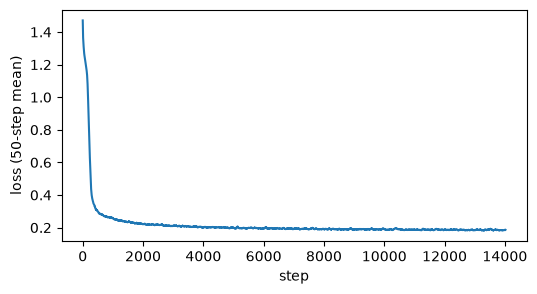

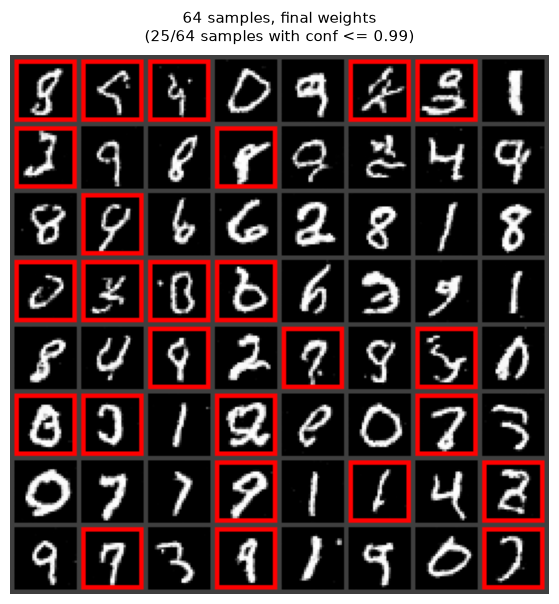

recognition score 70.1%   coverage not full
predicted-digit counts [174, 205, 184, 177, 246, 120, 164, 203, 288, 239]   (full coverage needs 140 of each)


In [11]:
two_blocks_per_level()

In [13]:
def two_blocks_group_norm():
    out_dir = Path("flow_matching_examples/two_blocks")
    out_dir.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.norm = nn.GroupNorm(4, cout)                     # <-- GroupNorm
            self.t = nn.Linear(tdim, cout)                        # one offset per channel

        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            return F.relu(self.c2(F.relu(h)))


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=16, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 30, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    @torch.no_grad()
    def sample(model, x, N=50):
        # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            x = x + model(x, t) / N
        return x


    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


250,193 weights
epoch 1: loss 0.3224  (9 s)
epoch 2: loss 0.2616  (17 s)
epoch 3: loss 0.2381  (26 s)
epoch 4: loss 0.2257  (34 s)
epoch 5: loss 0.2176  (43 s)
epoch 6: loss 0.2122  (52 s)
epoch 7: loss 0.2080  (60 s)
epoch 8: loss 0.2062  (69 s)
epoch 9: loss 0.2020  (78 s)
epoch 10: loss 0.2021  (86 s)
epoch 11: loss 0.1958  (95 s)
epoch 12: loss 0.1969  (103 s)
epoch 13: loss 0.1948  (111 s)
epoch 14: loss 0.1960  (120 s)
epoch 15: loss 0.1924  (128 s)
epoch 16: loss 0.1920  (137 s)
epoch 17: loss 0.1911  (146 s)
epoch 18: loss 0.1917  (154 s)
epoch 19: loss 0.1899  (163 s)
epoch 20: loss 0.1881  (171 s)
epoch 21: loss 0.1879  (180 s)
epoch 22: loss 0.1905  (188 s)
epoch 23: loss 0.1860  (197 s)
epoch 24: loss 0.1901  (206 s)
epoch 25: loss 0.1852  (215 s)
epoch 26: loss 0.1869  (223 s)
epoch 27: loss 0.1853  (232 s)
epoch 28: loss 0.1861  (241 s)
epoch 29: loss 0.1870  (249 s)
epoch 30: loss 0.1850  (258 s)


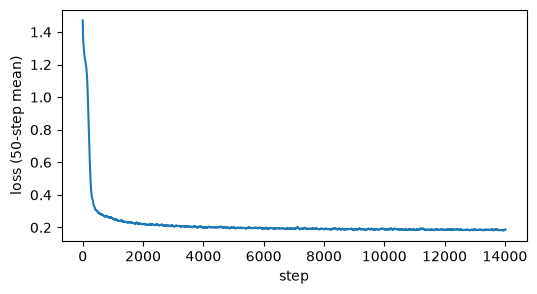

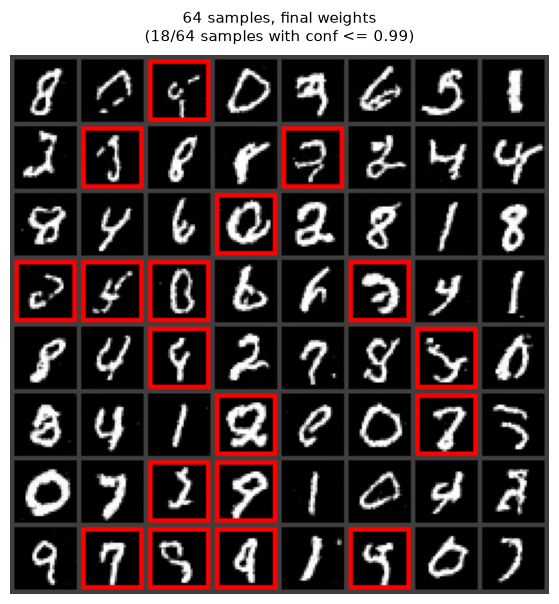

recognition score 69.2%   coverage not full
predicted-digit counts [252, 194, 154, 128, 283, 93, 212, 234, 299, 151]   (full coverage needs 140 of each)


In [14]:
two_blocks_group_norm()

### 4. Basic Performance Tuning

In [15]:
def two_blocks_residual():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            change = self.c2(F.relu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=16, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 30, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    @torch.no_grad()
    def sample(model, x, N=50):
        # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            x = x + model(x, t) / N
        return x


    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


254,849 weights
epoch 1: loss 0.2637  (10 s)
epoch 2: loss 0.2310  (19 s)
epoch 3: loss 0.2154  (28 s)
epoch 4: loss 0.2072  (37 s)
epoch 5: loss 0.2031  (47 s)
epoch 6: loss 0.1988  (56 s)
epoch 7: loss 0.1972  (65 s)
epoch 8: loss 0.1948  (74 s)
epoch 9: loss 0.1924  (84 s)
epoch 10: loss 0.1915  (93 s)
epoch 11: loss 0.1879  (102 s)
epoch 12: loss 0.1934  (111 s)
epoch 13: loss 0.1886  (120 s)
epoch 14: loss 0.1884  (130 s)
epoch 15: loss 0.1859  (139 s)
epoch 16: loss 0.1854  (148 s)
epoch 17: loss 0.1844  (157 s)
epoch 18: loss 0.1845  (166 s)
epoch 19: loss 0.1838  (176 s)
epoch 20: loss 0.1838  (185 s)
epoch 21: loss 0.1829  (195 s)
epoch 22: loss 0.1846  (204 s)
epoch 23: loss 0.1827  (213 s)
epoch 24: loss 0.1823  (222 s)
epoch 25: loss 0.1816  (231 s)
epoch 26: loss 0.1817  (240 s)
epoch 27: loss 0.1810  (250 s)
epoch 28: loss 0.1817  (259 s)
epoch 29: loss 0.1824  (268 s)
epoch 30: loss 0.1818  (277 s)


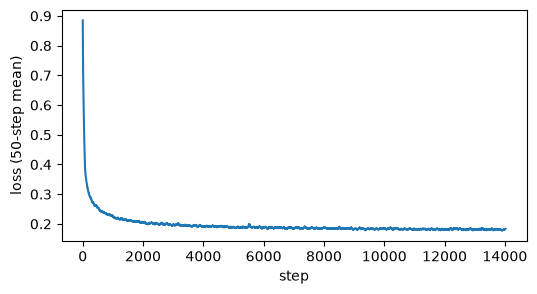

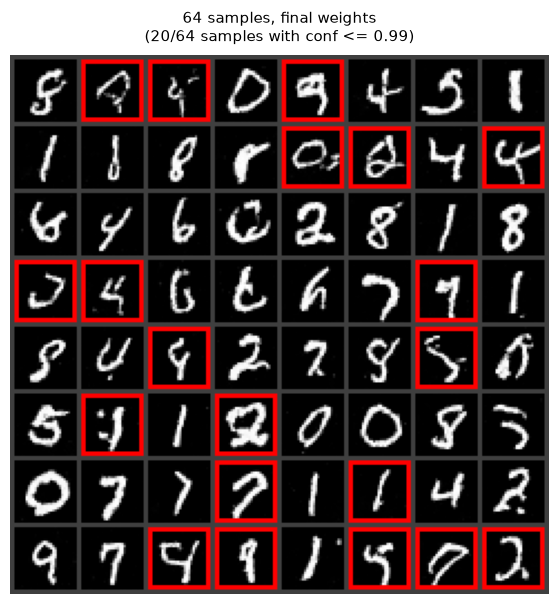

recognition score 70.5%   coverage full
predicted-digit counts [211, 242, 191, 155, 247, 145, 183, 252, 209, 165]   (full coverage needs 140 of each)


In [16]:
two_blocks_residual()

In [21]:
def two_blocks_residual_groupnorm():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.norm = nn.GroupNorm(4, cout)                     # <-- GroupNorm
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            change = self.c2(F.relu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=16, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 30, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    @torch.no_grad()
    def sample(model, x, N=50):
        # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            x = x + model(x, t) / N
        return x


    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


255,489 weights
epoch 1: loss 0.2636  (10 s)
epoch 2: loss 0.2291  (19 s)
epoch 3: loss 0.2154  (27 s)
epoch 4: loss 0.2067  (36 s)
epoch 5: loss 0.2032  (45 s)
epoch 6: loss 0.1990  (55 s)
epoch 7: loss 0.1962  (64 s)
epoch 8: loss 0.1961  (73 s)
epoch 9: loss 0.1926  (83 s)
epoch 10: loss 0.1910  (92 s)
epoch 11: loss 0.1878  (101 s)
epoch 12: loss 0.1898  (111 s)
epoch 13: loss 0.1887  (120 s)
epoch 14: loss 0.1886  (129 s)
epoch 15: loss 0.1876  (139 s)
epoch 16: loss 0.1852  (148 s)
epoch 17: loss 0.1835  (158 s)
epoch 18: loss 0.1838  (167 s)
epoch 19: loss 0.1843  (177 s)
epoch 20: loss 0.1840  (186 s)
epoch 21: loss 0.1827  (196 s)
epoch 22: loss 0.1828  (205 s)
epoch 23: loss 0.1829  (214 s)
epoch 24: loss 0.1830  (224 s)
epoch 25: loss 0.1808  (233 s)
epoch 26: loss 0.1831  (242 s)
epoch 27: loss 0.1812  (252 s)
epoch 28: loss 0.1823  (262 s)
epoch 29: loss 0.1821  (271 s)
epoch 30: loss 0.1819  (280 s)


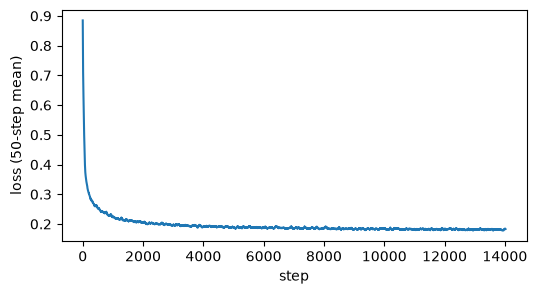

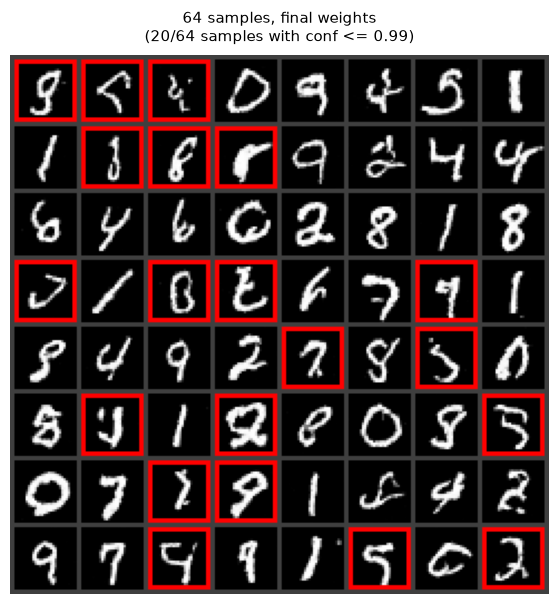

recognition score 69.8%   coverage full
predicted-digit counts [174, 209, 185, 172, 219, 147, 184, 251, 261, 198]   (full coverage needs 140 of each)


In [22]:
two_blocks_residual_groupnorm()

In [29]:
def two_blocks_residual_OT():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            change = self.c2(F.relu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=16, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 60, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
            _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
            x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    # @torch.no_grad()
    # def sample(model, x, N=50):
    #     # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
    #     for i in range(N):
    #         t = torch.full((len(x), 1), i / N, device=x.device)
    #         x = x + model(x, t) / N
    #     return x

    @torch.no_grad()
    def sample(model, x, N=25):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x


    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


254,849 weights
epoch 1: loss 0.2121  (11 s)
epoch 2: loss 0.1800  (21 s)
epoch 3: loss 0.1663  (31 s)
epoch 4: loss 0.1565  (41 s)
epoch 5: loss 0.1517  (51 s)
epoch 6: loss 0.1492  (62 s)
epoch 7: loss 0.1458  (72 s)
epoch 8: loss 0.1452  (83 s)
epoch 9: loss 0.1431  (93 s)
epoch 10: loss 0.1399  (104 s)
epoch 11: loss 0.1392  (115 s)
epoch 12: loss 0.1382  (125 s)
epoch 13: loss 0.1378  (135 s)
epoch 14: loss 0.1379  (146 s)
epoch 15: loss 0.1362  (157 s)
epoch 16: loss 0.1343  (167 s)
epoch 17: loss 0.1329  (178 s)
epoch 18: loss 0.1330  (188 s)
epoch 19: loss 0.1340  (198 s)
epoch 20: loss 0.1326  (208 s)
epoch 21: loss 0.1320  (218 s)
epoch 22: loss 0.1323  (229 s)
epoch 23: loss 0.1323  (239 s)
epoch 24: loss 0.1309  (249 s)
epoch 25: loss 0.1309  (260 s)
epoch 26: loss 0.1304  (270 s)
epoch 27: loss 0.1302  (280 s)
epoch 28: loss 0.1305  (290 s)
epoch 29: loss 0.1305  (301 s)
epoch 30: loss 0.1296  (311 s)
epoch 31: loss 0.1413  (321 s)
epoch 32: loss 0.1386  (332 s)
epoch 33: 

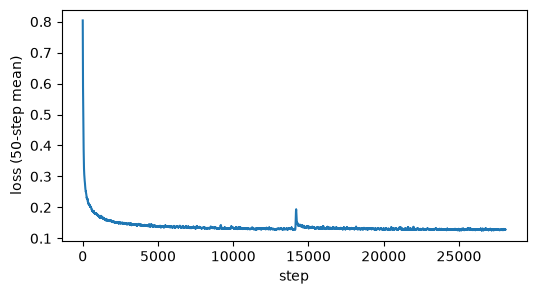

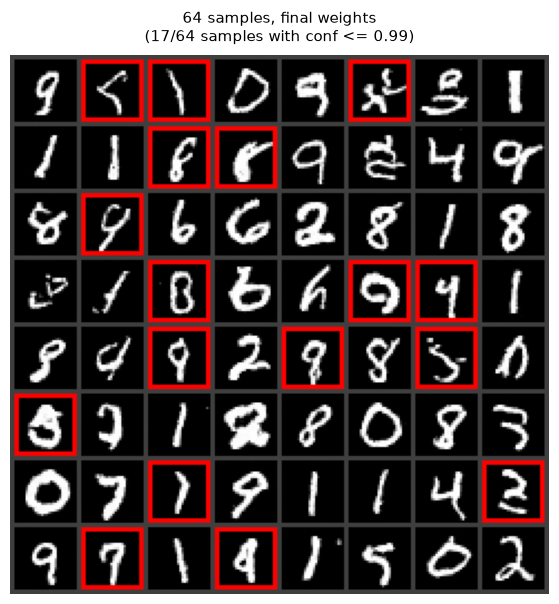

recognition score 75.6%   coverage not full
predicted-digit counts [157, 315, 174, 195, 196, 106, 171, 160, 293, 233]   (full coverage needs 140 of each)


In [30]:
two_blocks_residual_OT()

In [ ]:
def two_blocks_residual_OT_CLR():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            change = self.c2(F.relu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=64, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 60, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    STEPS, WARMUP = EPOCHS * math.ceil(len(X) / BATCH), 200
    def lr_factor(s):                                      # <-- warm up, then cosine decay to 0
        if s < WARMUP:
            return s / WARMUP
        return 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
            _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
            x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            sched.step() 
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    plt.figure(figsize=(6, 2.5)); plt.plot([LR * lr_factor(s) for s in range(STEPS)])
    plt.xlabel("step"); plt.ylabel("learning rate"); plt.show()


    @torch.no_grad()
    def sample(model, x, N=25):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x


    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


3,906,881 weights
epoch 1: loss 0.1721  (31 s)
epoch 2: loss 0.1493  (61 s)
epoch 3: loss 0.1445  (91 s)
epoch 4: loss 0.1364  (121 s)
epoch 5: loss 0.1358  (152 s)
epoch 6: loss 0.1345  (182 s)
epoch 7: loss 0.1320  (212 s)
epoch 8: loss 0.1320  (243 s)
epoch 9: loss 0.1316  (274 s)
epoch 10: loss 0.1290  (304 s)
epoch 11: loss 0.1310  (335 s)
epoch 12: loss 0.1313  (366 s)
epoch 13: loss 0.1285  (396 s)
epoch 14: loss 0.1284  (426 s)
epoch 15: loss 0.1265  (456 s)
epoch 16: loss 0.1265  (486 s)
epoch 17: loss 0.1246  (517 s)
epoch 18: loss 0.1244  (547 s)
epoch 19: loss 0.1252  (577 s)
epoch 20: loss 0.1243  (608 s)
epoch 21: loss 0.1233  (638 s)
epoch 22: loss 0.1232  (669 s)
epoch 23: loss 0.1238  (699 s)
epoch 24: loss 0.1224  (729 s)
epoch 25: loss 0.1218  (759 s)
epoch 26: loss 0.1214  (790 s)
epoch 27: loss 0.1216  (820 s)
epoch 28: loss 0.1221  (850 s)
epoch 29: loss 0.1208  (880 s)
epoch 30: loss 0.1201  (911 s)
epoch 31: loss 0.1204  (941 s)
epoch 32: loss 0.1211  (971 s)
ep

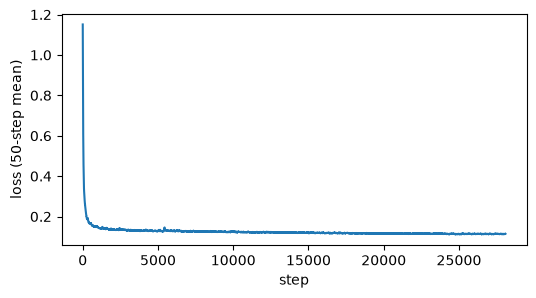

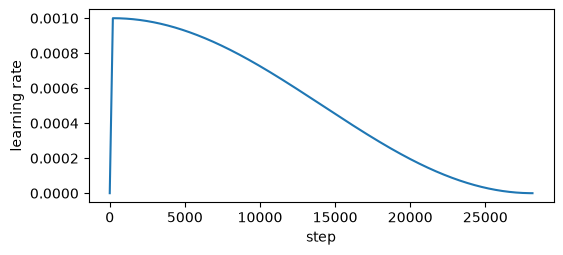

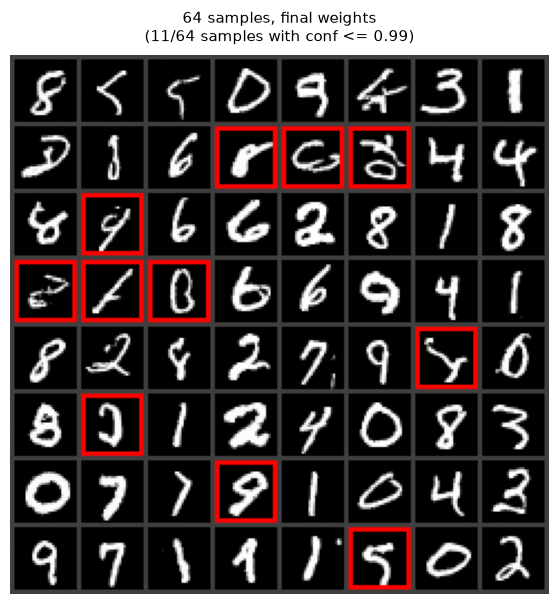

recognition score 85.4%   coverage full
predicted-digit counts [189, 249, 206, 215, 213, 151, 192, 182, 223, 180]   (full coverage needs 140 of each)


In [11]:
two_blocks_residual_OT_CLR()

In [43]:
def two_blocks_residual_OT_CLR_attention():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            change = self.c2(F.relu(h))
            return self.proj(x) + change


    class Attention(nn.Module):
        # <-- every position looks at every position: 49 x 49 weights at 7 x 7
        def __init__(self, c):
            super().__init__()
            self.norm = nn.GroupNorm(4, c)
            self.qkv = nn.Conv2d(c, 3 * c, 1)               # a query, key and value at each position
            self.out = nn.Conv2d(c, c, 1)
            nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)   # starts as the identity

        def forward(self, x):
            B, C, H, W = x.shape
            q, k, v = self.qkv(self.norm(x)).reshape(B, 3, C, H * W).unbind(1)   # each B x C x 49
            w = torch.softmax(q.transpose(1, 2) @ k / C ** 0.5, dim=-1)          # B x 49 x 49, rows sum to 1
            h = (v @ w.transpose(1, 2)).reshape(B, C, H, W)                      # weighted average of values
            return x + self.out(h)


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=32, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.attn = Attention(4 * c)                     # <-- attention at 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.attn(self.mid(F.max_pool2d(s2, 2), te))   # <-- attention
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 60, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    STEPS, WARMUP = EPOCHS * math.ceil(len(X) / BATCH), 200
    def lr_factor(s):                                      # <-- warm up, then cosine decay to 0
        if s < WARMUP:
            return s / WARMUP
        return 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
            _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
            x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            sched.step() 
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    plt.figure(figsize=(6, 2.5)); plt.plot([LR * lr_factor(s) for s in range(STEPS)])
    plt.xlabel("step"); plt.ylabel("learning rate"); plt.show()

    # @torch.no_grad()
    # def sample(model, x, N=50):
    #     # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
    #     for i in range(N):
    #         t = torch.full((len(x), 1), i / N, device=x.device)
    #         x = x + model(x, t) / N
    #     return x

    @torch.no_grad()
    def sample(model, x, N=25):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x


    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


1,056,193 weights
epoch 1: loss 0.1978  (16 s)
epoch 2: loss 0.1616  (31 s)
epoch 3: loss 0.1492  (45 s)
epoch 4: loss 0.1424  (59 s)
epoch 5: loss 0.1396  (73 s)
epoch 6: loss 0.1386  (87 s)
epoch 7: loss 0.1352  (101 s)
epoch 8: loss 0.1346  (115 s)
epoch 9: loss 0.1345  (129 s)
epoch 10: loss 0.1314  (142 s)
epoch 11: loss 0.1298  (156 s)
epoch 12: loss 0.1304  (170 s)
epoch 13: loss 0.1285  (184 s)
epoch 14: loss 0.1301  (198 s)
epoch 15: loss 0.1281  (212 s)
epoch 16: loss 0.1272  (225 s)
epoch 17: loss 0.1258  (239 s)
epoch 18: loss 0.1270  (253 s)
epoch 19: loss 0.1255  (267 s)
epoch 20: loss 0.1248  (281 s)
epoch 21: loss 0.1270  (294 s)
epoch 22: loss 0.1244  (308 s)
epoch 23: loss 0.1245  (322 s)
epoch 24: loss 0.1240  (336 s)
epoch 25: loss 0.1225  (350 s)
epoch 26: loss 0.1218  (364 s)
epoch 27: loss 0.1237  (377 s)
epoch 28: loss 0.1223  (391 s)
epoch 29: loss 0.1221  (405 s)
epoch 30: loss 0.1208  (419 s)
epoch 31: loss 0.1211  (433 s)
epoch 32: loss 0.1222  (446 s)
epoch

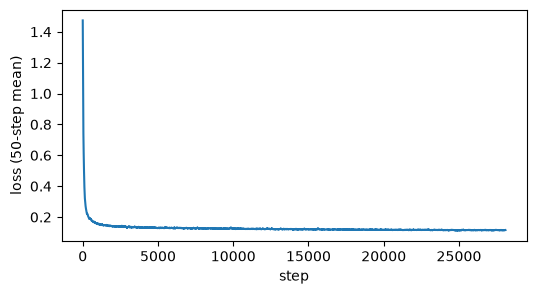

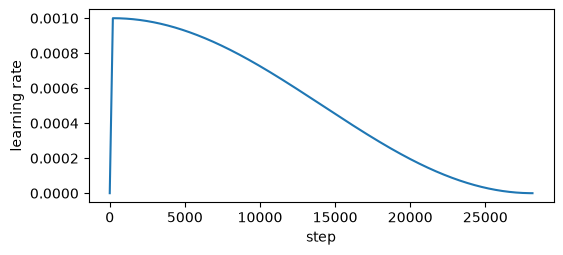

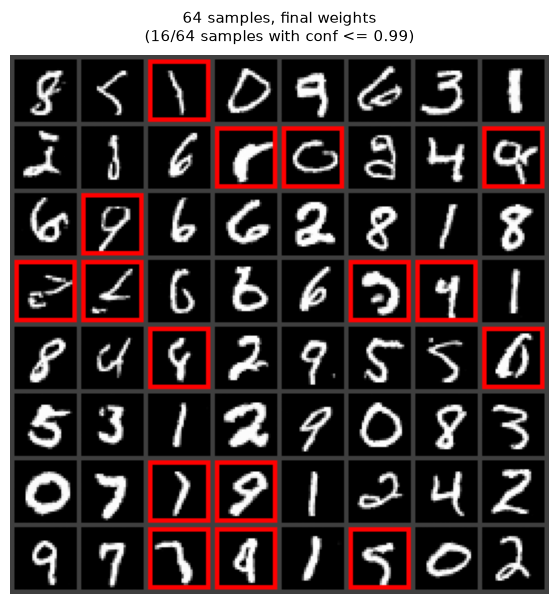

recognition score 82.3%   coverage full
predicted-digit counts [195, 248, 210, 216, 202, 152, 193, 188, 209, 187]   (full coverage needs 140 of each)


In [44]:
two_blocks_residual_OT_CLR_attention()

In [7]:
def two_blocks_residual_OT_CLR_EMA():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            change = self.c2(F.relu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=32, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 60, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)

    STEPS, WARMUP = EPOCHS * math.ceil(len(X) / BATCH), 200
    def lr_factor(s):                                      # <-- warm up, then cosine decay to 0
        if s < WARMUP:
            return s / WARMUP
        return 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    BETA = 0.999                                           # <-- the average spans about 1,000 steps
    ema = copy.deepcopy(net).requires_grad_(False)          # <-- the averaged copy

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
            _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
            x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            sched.step() 
            with torch.no_grad():                           # <-- ema <- BETA ema + (1 - BETA) net
                for e, p in zip(ema.parameters(), net.parameters()):
                    e.lerp_(p, 1 - BETA)
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    plt.figure(figsize=(6, 2.5)); plt.plot([LR * lr_factor(s) for s in range(STEPS)])
    plt.xlabel("step"); plt.ylabel("learning rate"); plt.show()

    @torch.no_grad()
    def sample(model, x, N=25):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x


    ema.eval()
    net.eval()

    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(ema, Z), title="64 samples, EMA weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(ema, z[i:i + 500])) for i in range(0, 2000, 500)])
    
    # 2. Score raw net weights (for direct comparison)
    u8_net = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])
    score_net, counts_net, _, _ = recognition(u8_net)
    print(f"Raw net score: {score_net:.1%}")

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


989,889 weights
epoch 1: loss 0.1966  (15 s)
epoch 2: loss 0.1598  (29 s)
epoch 3: loss 0.1499  (43 s)
epoch 4: loss 0.1411  (57 s)
epoch 5: loss 0.1398  (71 s)
epoch 6: loss 0.1388  (85 s)
epoch 7: loss 0.1348  (100 s)
epoch 8: loss 0.1367  (114 s)
epoch 9: loss 0.1330  (128 s)
epoch 10: loss 0.1306  (142 s)
epoch 11: loss 0.1308  (156 s)
epoch 12: loss 0.1320  (171 s)
epoch 13: loss 0.1294  (185 s)
epoch 14: loss 0.1294  (199 s)
epoch 15: loss 0.1281  (213 s)
epoch 16: loss 0.1277  (227 s)
epoch 17: loss 0.1259  (241 s)
epoch 18: loss 0.1275  (256 s)
epoch 19: loss 0.1266  (270 s)
epoch 20: loss 0.1259  (285 s)
epoch 21: loss 0.1250  (299 s)
epoch 22: loss 0.1266  (314 s)
epoch 23: loss 0.1251  (328 s)
epoch 24: loss 0.1240  (343 s)
epoch 25: loss 0.1231  (357 s)
epoch 26: loss 0.1226  (371 s)
epoch 27: loss 0.1234  (386 s)
epoch 28: loss 0.1227  (400 s)
epoch 29: loss 0.1226  (414 s)
epoch 30: loss 0.1215  (429 s)
epoch 31: loss 0.1220  (443 s)
epoch 32: loss 0.1229  (457 s)
epoch 3

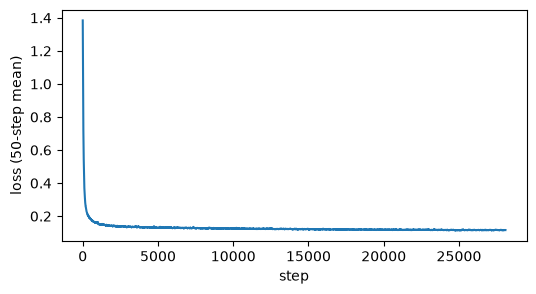

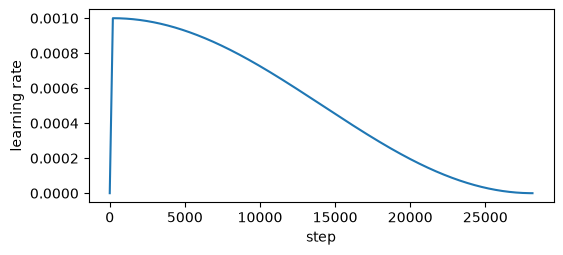

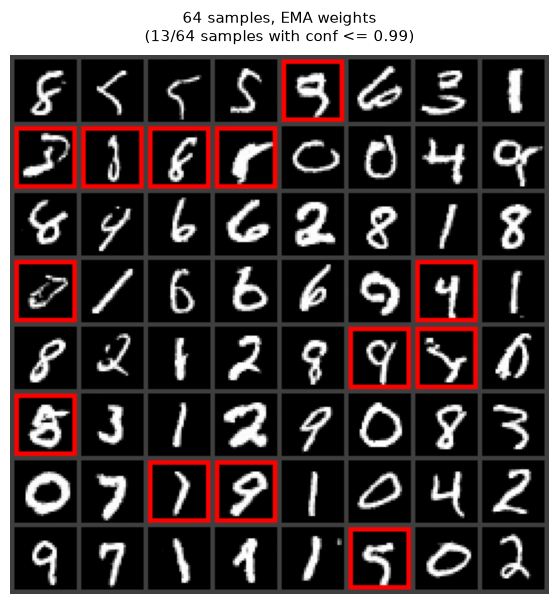

Raw net score: 84.0%
recognition score 84.0%   coverage full
predicted-digit counts [187, 238, 220, 213, 209, 161, 183, 184, 215, 190]   (full coverage needs 140 of each)


In [8]:
two_blocks_residual_OT_CLR_EMA()

In [9]:
def two_blocks_residual_OT_CLR_Beta_t():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.c1(x) + self.t(te)[:, :, None, None]
            change = self.c2(F.relu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=32, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 60, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    STEPS, WARMUP = EPOCHS * math.ceil(len(X) / BATCH), 200
    def lr_factor(s):                                      # <-- warm up, then cosine decay to 0
        if s < WARMUP:
            return s / WARMUP
        return 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
            _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
            x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
            t = 1 - torch.distributions.Beta(1.5, 1.0).sample((len(x1), 1)).to(dev)   # <-- more t near 0
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            sched.step() 
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    plt.figure(figsize=(6, 2.5)); plt.plot([LR * lr_factor(s) for s in range(STEPS)])
    plt.xlabel("step"); plt.ylabel("learning rate"); plt.show()

    @torch.no_grad()
    def sample(model, x, N=25):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x

    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


989,889 weights
epoch 1: loss 0.1874  (15 s)
epoch 2: loss 0.1585  (29 s)
epoch 3: loss 0.1474  (43 s)
epoch 4: loss 0.1429  (57 s)
epoch 5: loss 0.1419  (72 s)
epoch 6: loss 0.1390  (86 s)
epoch 7: loss 0.1360  (100 s)
epoch 8: loss 0.1351  (113 s)
epoch 9: loss 0.1348  (127 s)
epoch 10: loss 0.1339  (141 s)
epoch 11: loss 0.1323  (156 s)
epoch 12: loss 0.1317  (170 s)
epoch 13: loss 0.1335  (184 s)
epoch 14: loss 0.1317  (198 s)
epoch 15: loss 0.1311  (212 s)
epoch 16: loss 0.1307  (226 s)
epoch 17: loss 0.1302  (240 s)
epoch 18: loss 0.1291  (255 s)
epoch 19: loss 0.1289  (269 s)
epoch 20: loss 0.1296  (283 s)
epoch 21: loss 0.1281  (297 s)
epoch 22: loss 0.1285  (311 s)
epoch 23: loss 0.1267  (325 s)
epoch 24: loss 0.1306  (340 s)
epoch 25: loss 0.1282  (354 s)
epoch 26: loss 0.1285  (368 s)
epoch 27: loss 0.1271  (382 s)
epoch 28: loss 0.1263  (396 s)
epoch 29: loss 0.1263  (411 s)
epoch 30: loss 0.1268  (425 s)
epoch 31: loss 0.1258  (439 s)
epoch 32: loss 0.1247  (453 s)
epoch 3

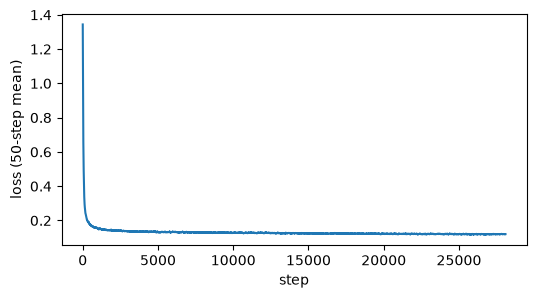

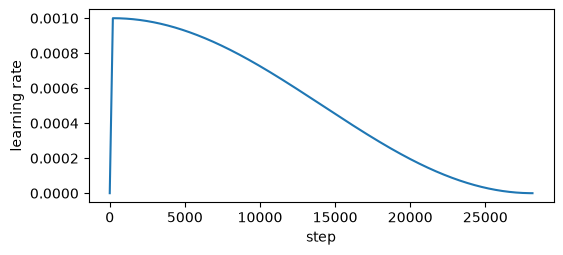

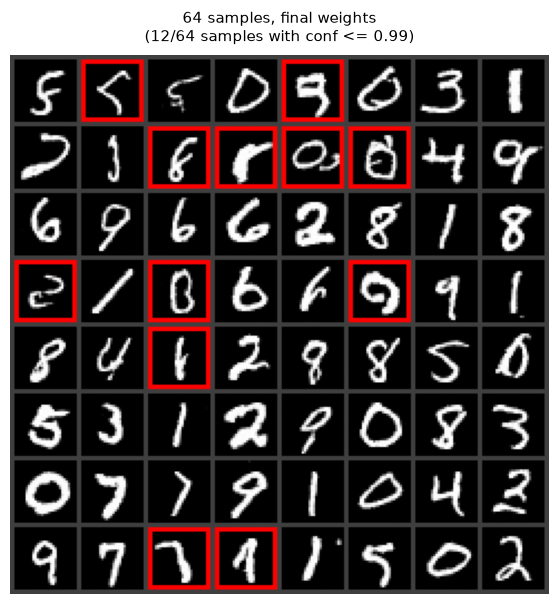

recognition score 84.1%   coverage full
predicted-digit counts [197, 256, 201, 203, 211, 156, 198, 179, 208, 191]   (full coverage needs 140 of each)


In [10]:
two_blocks_residual_OT_CLR_Beta_t()

In [3]:
def two_blocks_residual_OT_CLR_FiLM():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.t = nn.Linear(tdim, 2 * cout)                    # <-- a scale and an offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            s, b = self.t(te)[:, :, None, None].chunk(2, 1)
            h = self.c1(x) * (1 + s) + b                          # <-- t scales and shifts
            change = self.c2(F.relu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=32, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    EPOCHS, BATCH, LR = 60, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    STEPS, WARMUP = EPOCHS * math.ceil(len(X) / BATCH), 200
    def lr_factor(s):                                      # <-- warm up, then cosine decay to 0
        if s < WARMUP:
            return s / WARMUP
        return 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
            _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
            x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            sched.step() 
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    plt.figure(figsize=(6, 2.5)); plt.plot([LR * lr_factor(s) for s in range(STEPS)])
    plt.xlabel("step"); plt.ylabel("learning rate"); plt.show()

    @torch.no_grad()
    def sample(model, x, N=25):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x


    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


1,011,009 weights
epoch 1: loss 0.1818  (16 s)
epoch 2: loss 0.1502  (32 s)
epoch 3: loss 0.1429  (47 s)
epoch 4: loss 0.1388  (63 s)
epoch 5: loss 0.1352  (78 s)
epoch 6: loss 0.1338  (93 s)
epoch 7: loss 0.1331  (109 s)
epoch 8: loss 0.1315  (124 s)
epoch 9: loss 0.1298  (139 s)
epoch 10: loss 0.1284  (155 s)
epoch 11: loss 0.1262  (171 s)
epoch 12: loss 0.1291  (187 s)
epoch 13: loss 0.1258  (202 s)
epoch 14: loss 0.1265  (217 s)
epoch 15: loss 0.1244  (231 s)
epoch 16: loss 0.1241  (246 s)
epoch 17: loss 0.1226  (261 s)
epoch 18: loss 0.1230  (275 s)
epoch 19: loss 0.1226  (290 s)
epoch 20: loss 0.1245  (305 s)
epoch 21: loss 0.1215  (320 s)
epoch 22: loss 0.1212  (335 s)
epoch 23: loss 0.1221  (349 s)
epoch 24: loss 0.1212  (364 s)
epoch 25: loss 0.1207  (378 s)
epoch 26: loss 0.1198  (393 s)
epoch 27: loss 0.1207  (407 s)
epoch 28: loss 0.1201  (422 s)
epoch 29: loss 0.1203  (436 s)
epoch 30: loss 0.1187  (451 s)
epoch 31: loss 0.1194  (465 s)
epoch 32: loss 0.1204  (480 s)
epoch

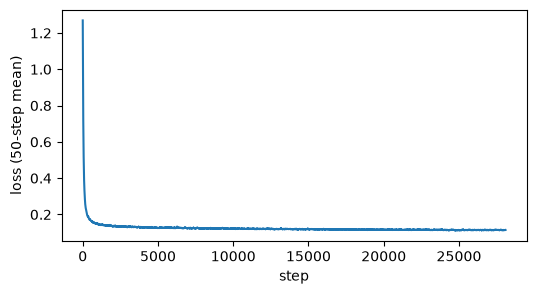

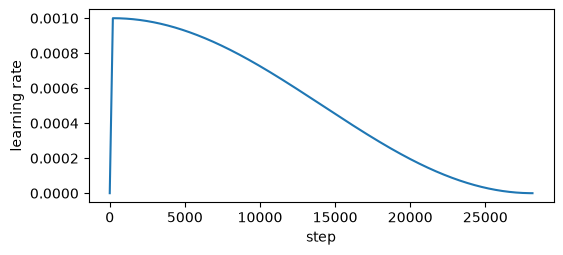

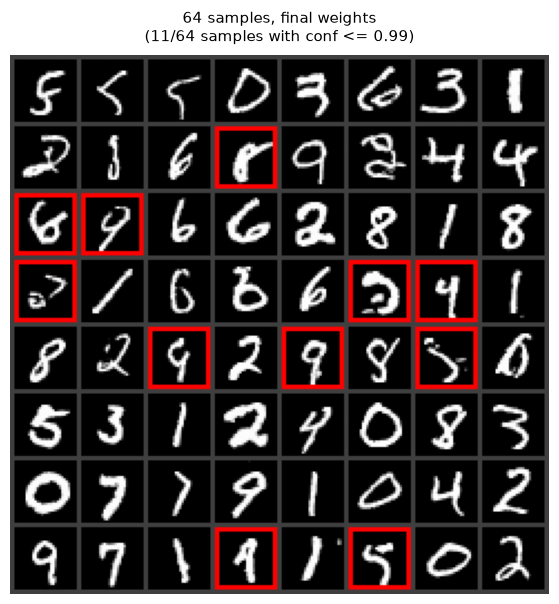

recognition score 83.8%   coverage full
predicted-digit counts [188, 253, 218, 206, 208, 152, 190, 175, 218, 192]   (full coverage needs 140 of each)


In [9]:
two_blocks_residual_OT_CLR_FiLM()

In [15]:
def two_blocks_residual_OT_CLR_GroupNorm():
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.norm = nn.GroupNorm(4, cout)                     # <-- GroupNorm
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.norm(self.c1(x)) + self.t(te)[:, :, None, None]
            change = self.c2(F.silu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=64, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    CKPT = str("Report/Results/trial20-checkpoint.pt")
    def save(net, opt, epoch, losses):                     # <-- everything needed to continue
        ck = {"net": net.state_dict(), "opt": opt.state_dict(), "epoch": epoch, "losses": losses}
        torch.save(ck, CKPT + ".tmp")
        os.replace(CKPT + ".tmp", CKPT)                    # <-- an interrupted save leaves the last checkpoint intact

    EPOCHS, BATCH, LR = 80, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    STEPS, WARMUP = EPOCHS * math.ceil(len(X) / BATCH), 200
    def lr_factor(s):                                      # <-- warm up, then cosine decay to 0
        if s < WARMUP:
            return s / WARMUP
        return 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
            _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
            x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            sched.step() 
            losses.append(loss.item())
        save(net, opt, epoch + 1, losses)              # <-- after every epoch
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    plt.figure(figsize=(6, 2.5)); plt.plot([LR * lr_factor(s) for s in range(STEPS)])
    plt.xlabel("step"); plt.ylabel("learning rate"); plt.show()


    @torch.no_grad()
    def sample(model, x, N=50):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x

    

    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])
    np.save(str("Report/Results/trial20-samples.npy"), u8.numpy())

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


3,909,441 weights
epoch 1: loss 0.1639  (33 s)
epoch 2: loss 0.1438  (65 s)
epoch 3: loss 0.1398  (97 s)
epoch 4: loss 0.1338  (130 s)
epoch 5: loss 0.1315  (162 s)
epoch 6: loss 0.1316  (195 s)
epoch 7: loss 0.1290  (228 s)
epoch 8: loss 0.1294  (261 s)
epoch 9: loss 0.1274  (294 s)
epoch 10: loss 0.1260  (324 s)
epoch 11: loss 0.1239  (354 s)
epoch 12: loss 0.1247  (383 s)
epoch 13: loss 0.1239  (413 s)
epoch 14: loss 0.1246  (443 s)
epoch 15: loss 0.1229  (473 s)
epoch 16: loss 0.1225  (503 s)
epoch 17: loss 0.1215  (533 s)
epoch 18: loss 0.1214  (563 s)
epoch 19: loss 0.1215  (593 s)
epoch 20: loss 0.1214  (623 s)
epoch 21: loss 0.1203  (653 s)
epoch 22: loss 0.1200  (683 s)
epoch 23: loss 0.1204  (714 s)
epoch 24: loss 0.1199  (744 s)
epoch 25: loss 0.1194  (774 s)
epoch 26: loss 0.1187  (804 s)
epoch 27: loss 0.1196  (834 s)
epoch 28: loss 0.1190  (864 s)
epoch 29: loss 0.1186  (894 s)
epoch 30: loss 0.1177  (924 s)
epoch 31: loss 0.1184  (956 s)
epoch 32: loss 0.1187  (988 s)
ep

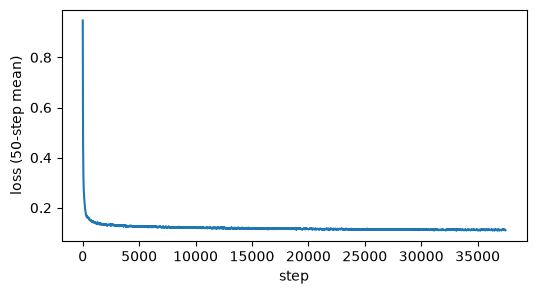

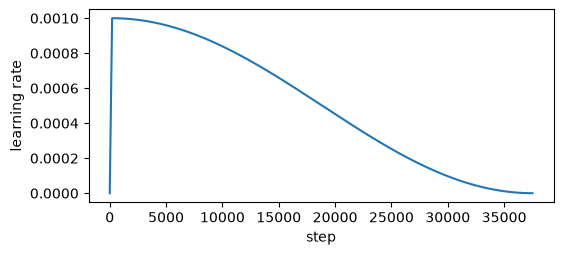

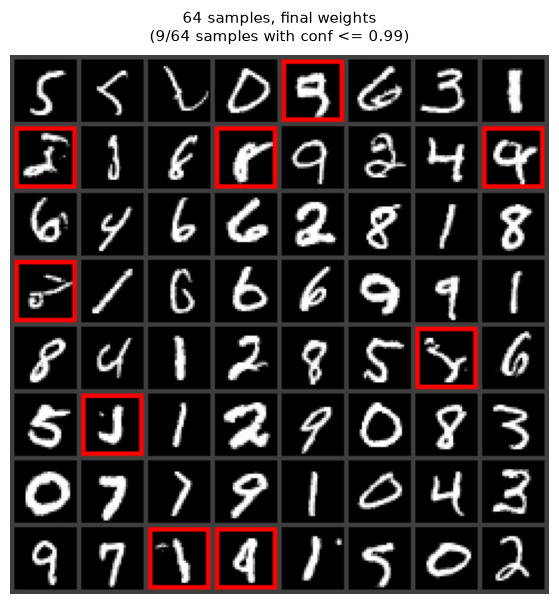

recognition score 86.5%   coverage full
predicted-digit counts [191, 258, 217, 202, 214, 146, 200, 172, 220, 180]   (full coverage needs 140 of each)


In [16]:
two_blocks_residual_OT_CLR_GroupNorm()

In [ ]:
def resume_trial20(total_epochs=120):
    torch.manual_seed(5561)
    X = xtr.to(dev)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.norm = nn.GroupNorm(4, cout)                     # <-- GroupNorm
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.norm(self.c1(x)) + self.t(te)[:, :, None, None]
            change = self.c2(F.silu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=64, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    CKPT = "Report/Results/trial20-checkpoint.pt"
    BATCH, LR = 128, 1e-3

    def save(net, opt, epoch, losses):                     # <-- everything needed to continue
        ck = {"net": net.state_dict(), "opt": opt.state_dict(), "epoch": epoch, "losses": losses}
        torch.save(ck, CKPT + ".tmp")
        os.replace(CKPT + ".tmp", CKPT)                    # <-- an interrupted save leaves the last checkpoint intact

    def load():                                            # <-- a new network and optimizer, then the checkpoint if any
        net = UNet().to(dev)
        opt = torch.optim.Adam(net.parameters(), lr=LR)
        if not os.path.exists(CKPT):
            return net, opt, 0, []
        ck = torch.load(CKPT, map_location=dev)
        net.load_state_dict(ck["net"])
        opt.load_state_dict(ck["opt"])                     # <-- Adam's running averages, not only the weights
        print(f"resuming after epoch {ck['epoch']}")
        return net, opt, ck["epoch"], ck["losses"]

    def train_until(last_epoch):
        net, opt, start, losses = load()

        STEPS = total_epochs * math.ceil(len(X) / BATCH)
        WARMUP = 200
        def lr_factor(s):
            if s < WARMUP:
                return s / WARMUP
            return 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP)))
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

        steps_done = start * math.ceil(len(X) / BATCH)
        for _ in range(steps_done):
            sched.step()

        t0 = time.time()
        for epoch in range(start, last_epoch):              # <-- Corrected range
            perm = torch.randperm(len(X), device=dev)
            for i in range(0, len(X), BATCH):
                x1 = X[perm[i:i + BATCH]]                      # data
                x0 = torch.randn_like(x1)                       # noise
                d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
                _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
                x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
                t = 1 - torch.distributions.Beta(1.5, 1.0).sample((len(x1), 1)).to(dev)   # <-- more t near 0
                tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
                xt = (1 - tb) * x0 + tb * x1
                loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
                opt.zero_grad(); loss.backward(); opt.step()
                sched.step() 
                losses.append(loss.item())
            save(net, opt, epoch + 1, losses)              # <-- after every epoch
            print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")
        return net, losses                                 # <-- Return added

    net, losses = train_until(total_epochs)
    
    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()


    @torch.no_grad()
    def sample(model, x, N=50):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x

    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])
    np.save(str("Report/Results/trial20-samples.npy"), u8.numpy())

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


resuming after epoch 120


c:\Users\yashp\miniconda3\envs\flow_matching\Lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


epoch 121: loss 0.1111  (33 s)
epoch 122: loss 0.1109  (65 s)
epoch 123: loss 0.1112  (97 s)
epoch 124: loss 0.1105  (130 s)
epoch 125: loss 0.1110  (162 s)
epoch 126: loss 0.1118  (196 s)
epoch 127: loss 0.1111  (229 s)
epoch 128: loss 0.1119  (261 s)
epoch 129: loss 0.1114  (294 s)
epoch 130: loss 0.1111  (328 s)
epoch 131: loss 0.1103  (361 s)
epoch 132: loss 0.1107  (394 s)
epoch 133: loss 0.1108  (428 s)
epoch 134: loss 0.1118  (461 s)
epoch 135: loss 0.1103  (493 s)
epoch 136: loss 0.1105  (526 s)
epoch 137: loss 0.1099  (558 s)
epoch 138: loss 0.1103  (591 s)
epoch 139: loss 0.1104  (624 s)
epoch 140: loss 0.1107  (658 s)
epoch 141: loss 0.1103  (692 s)
epoch 142: loss 0.1098  (725 s)
epoch 143: loss 0.1111  (758 s)
epoch 144: loss 0.1106  (791 s)
epoch 145: loss 0.1106  (824 s)
epoch 146: loss 0.1099  (858 s)
epoch 147: loss 0.1104  (891 s)
epoch 148: loss 0.1107  (924 s)
epoch 149: loss 0.1103  (958 s)
epoch 150: loss 0.1096  (992 s)
epoch 151: loss 0.1108  (1025 s)
epoch 152:

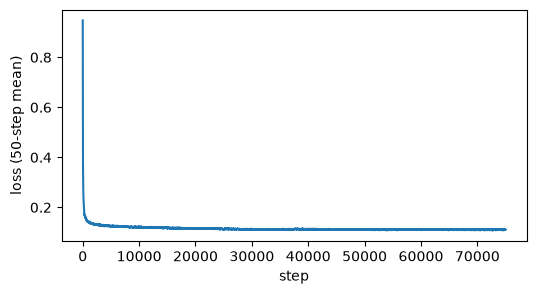

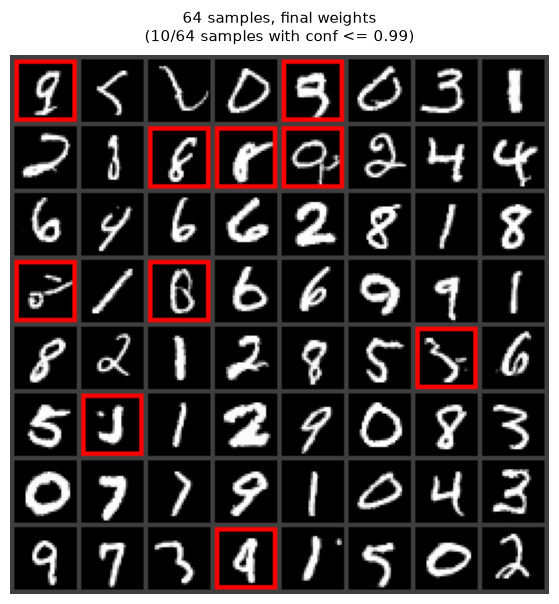

recognition score 87.2%   coverage full
predicted-digit counts [195, 268, 205, 217, 203, 145, 194, 180, 214, 179]   (full coverage needs 140 of each)


In [20]:
resume_trial20(total_epochs=160)

resuming after epoch 160


c:\Users\yashp\miniconda3\envs\flow_matching\Lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


epoch 161: loss 0.1126  (35 s)
epoch 162: loss 0.1126  (69 s)
epoch 163: loss 0.1130  (104 s)
epoch 164: loss 0.1124  (139 s)
epoch 165: loss 0.1129  (174 s)
epoch 166: loss 0.1140  (209 s)
epoch 167: loss 0.1129  (244 s)
epoch 168: loss 0.1139  (279 s)
epoch 169: loss 0.1136  (314 s)
epoch 170: loss 0.1131  (349 s)
epoch 171: loss 0.1123  (384 s)
epoch 172: loss 0.1131  (419 s)
epoch 173: loss 0.1130  (454 s)
epoch 174: loss 0.1140  (489 s)
epoch 175: loss 0.1124  (524 s)
epoch 176: loss 0.1127  (559 s)
epoch 177: loss 0.1120  (594 s)
epoch 178: loss 0.1124  (629 s)
epoch 179: loss 0.1125  (664 s)
epoch 180: loss 0.1129  (699 s)
epoch 181: loss 0.1122  (734 s)
epoch 182: loss 0.1120  (769 s)
epoch 183: loss 0.1132  (804 s)
epoch 184: loss 0.1125  (839 s)
epoch 185: loss 0.1124  (874 s)
epoch 186: loss 0.1119  (909 s)
epoch 187: loss 0.1124  (944 s)
epoch 188: loss 0.1126  (979 s)
epoch 189: loss 0.1123  (1014 s)
epoch 190: loss 0.1116  (1049 s)
epoch 191: loss 0.1124  (1084 s)
epoch 1

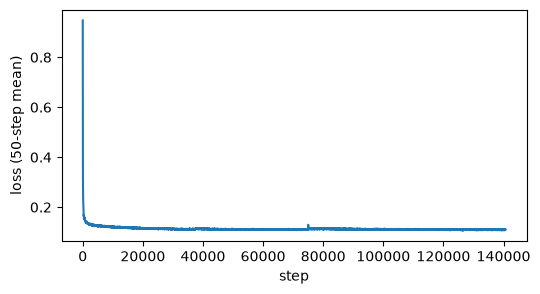

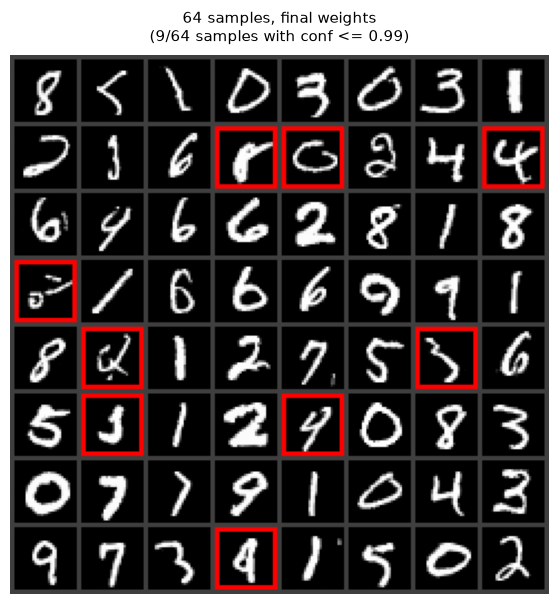

recognition score 88.8%   coverage full
predicted-digit counts [186, 267, 204, 207, 209, 146, 213, 178, 205, 185]   (full coverage needs 140 of each)


In [24]:
resume_trial20(total_epochs=300)

resuming after epoch 300
epoch 301: loss 0.1086  (37 s)
epoch 302: loss 0.1084  (72 s)
epoch 303: loss 0.1089  (106 s)
epoch 304: loss 0.1081  (141 s)
epoch 305: loss 0.1087  (175 s)
epoch 306: loss 0.1095  (210 s)
epoch 307: loss 0.1089  (245 s)
epoch 308: loss 0.1096  (279 s)
epoch 309: loss 0.1092  (314 s)
epoch 310: loss 0.1089  (349 s)
epoch 311: loss 0.1081  (383 s)
epoch 312: loss 0.1085  (418 s)
epoch 313: loss 0.1087  (453 s)
epoch 314: loss 0.1097  (487 s)
epoch 315: loss 0.1081  (522 s)
epoch 316: loss 0.1085  (556 s)
epoch 317: loss 0.1079  (591 s)
epoch 318: loss 0.1084  (626 s)
epoch 319: loss 0.1085  (660 s)
epoch 320: loss 0.1087  (695 s)
epoch 321: loss 0.1084  (730 s)
epoch 322: loss 0.1079  (764 s)
epoch 323: loss 0.1092  (799 s)
epoch 324: loss 0.1088  (833 s)
epoch 325: loss 0.1087  (868 s)
epoch 326: loss 0.1080  (903 s)
epoch 327: loss 0.1086  (937 s)
epoch 328: loss 0.1090  (972 s)
epoch 329: loss 0.1085  (1006 s)
epoch 330: loss 0.1078  (1041 s)
epoch 331: loss

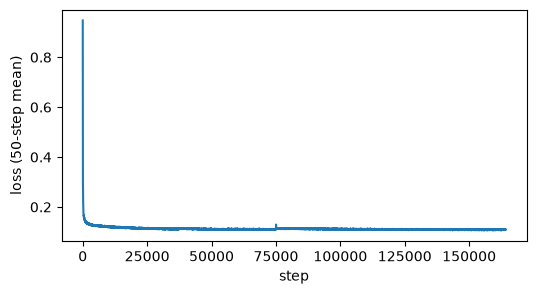

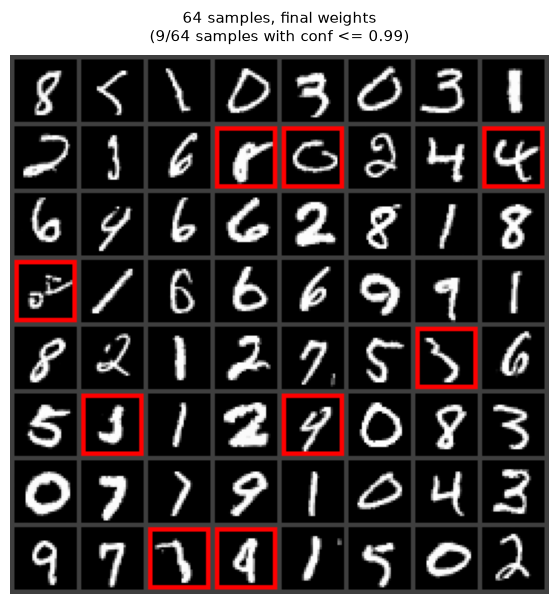

recognition score 89.1%   coverage full
predicted-digit counts [192, 267, 207, 210, 207, 147, 216, 172, 203, 179]   (full coverage needs 140 of each)


In [25]:
resume_trial20(total_epochs=350)

resuming after epoch 350
epoch 351: loss 0.1080  (35 s)
epoch 352: loss 0.1078  (69 s)
epoch 353: loss 0.1082  (104 s)
epoch 354: loss 0.1076  (139 s)
epoch 355: loss 0.1081  (173 s)
epoch 356: loss 0.1089  (208 s)
epoch 357: loss 0.1084  (243 s)
epoch 358: loss 0.1092  (277 s)
epoch 359: loss 0.1087  (312 s)
epoch 360: loss 0.1085  (347 s)
epoch 361: loss 0.1077  (382 s)
epoch 362: loss 0.1081  (416 s)
epoch 363: loss 0.1084  (451 s)
epoch 364: loss 0.1093  (486 s)
epoch 365: loss 0.1078  (520 s)
epoch 366: loss 0.1082  (555 s)
epoch 367: loss 0.1076  (590 s)
epoch 368: loss 0.1081  (625 s)
epoch 369: loss 0.1082  (660 s)
epoch 370: loss 0.1084  (694 s)
epoch 371: loss 0.1082  (729 s)
epoch 372: loss 0.1077  (764 s)
epoch 373: loss 0.1090  (799 s)
epoch 374: loss 0.1086  (834 s)
epoch 375: loss 0.1086  (868 s)
epoch 376: loss 0.1078  (903 s)
epoch 377: loss 0.1084  (938 s)
epoch 378: loss 0.1089  (973 s)
epoch 379: loss 0.1084  (1008 s)
epoch 380: loss 0.1077  (1042 s)
epoch 381: loss

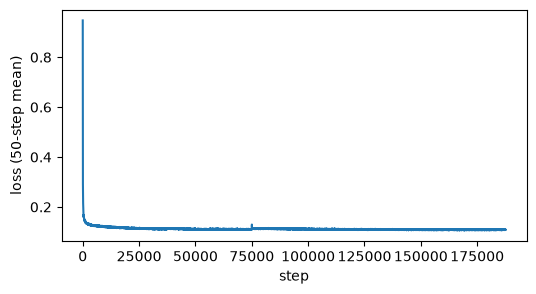

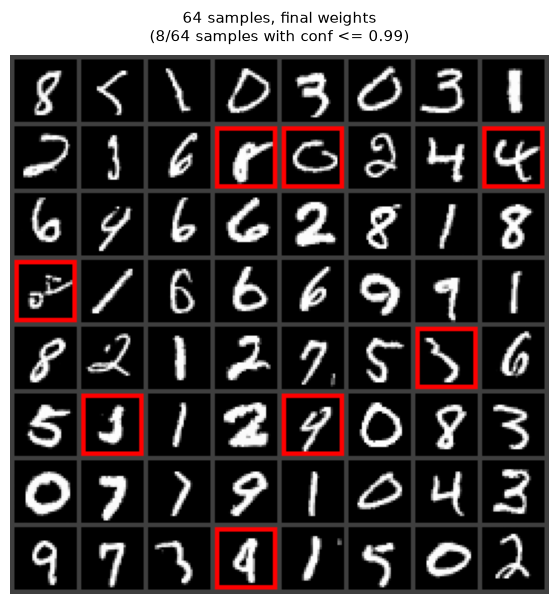

recognition score 89.6%   coverage full
predicted-digit counts [191, 268, 203, 213, 206, 146, 212, 173, 209, 179]   (full coverage needs 140 of each)


In [26]:
resume_trial20(total_epochs=400)

resuming after epoch 400
epoch 401: loss 0.1075  (35 s)
epoch 402: loss 0.1075  (69 s)
epoch 403: loss 0.1078  (104 s)
epoch 404: loss 0.1073  (139 s)
epoch 405: loss 0.1078  (173 s)
epoch 406: loss 0.1086  (208 s)
epoch 407: loss 0.1081  (243 s)
epoch 408: loss 0.1089  (278 s)
epoch 409: loss 0.1085  (313 s)
epoch 410: loss 0.1082  (347 s)
epoch 411: loss 0.1074  (382 s)
epoch 412: loss 0.1078  (417 s)
epoch 413: loss 0.1081  (452 s)
epoch 414: loss 0.1091  (487 s)
epoch 415: loss 0.1076  (523 s)
epoch 416: loss 0.1080  (558 s)
epoch 417: loss 0.1074  (593 s)
epoch 418: loss 0.1079  (628 s)
epoch 419: loss 0.1081  (663 s)
epoch 420: loss 0.1083  (698 s)
epoch 421: loss 0.1081  (733 s)
epoch 422: loss 0.1075  (768 s)
epoch 423: loss 0.1088  (803 s)
epoch 424: loss 0.1085  (838 s)
epoch 425: loss 0.1084  (873 s)
epoch 426: loss 0.1077  (908 s)
epoch 427: loss 0.1083  (942 s)
epoch 428: loss 0.1088  (977 s)
epoch 429: loss 0.1083  (1012 s)
epoch 430: loss 0.1076  (1047 s)
epoch 431: loss

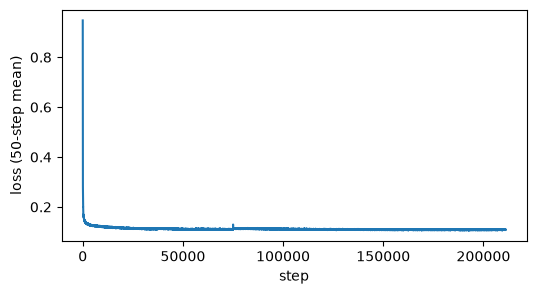

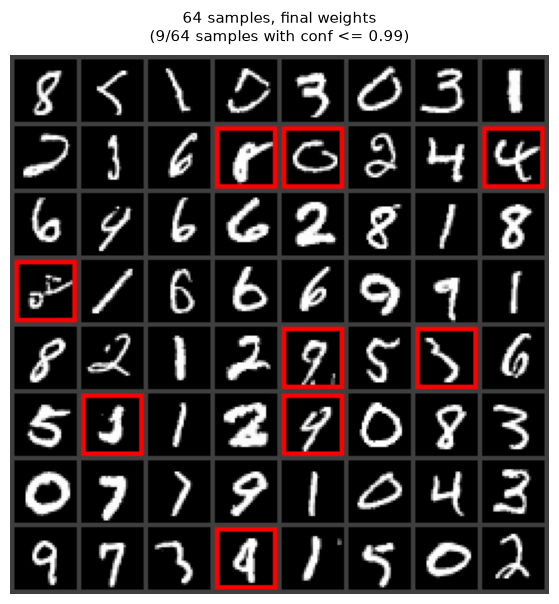

recognition score 89.2%   coverage full
predicted-digit counts [192, 269, 207, 213, 202, 142, 212, 174, 213, 176]   (full coverage needs 140 of each)


In [27]:
resume_trial20(total_epochs=450)

resuming after epoch 450
epoch 451: loss 0.1072  (34 s)
epoch 452: loss 0.1072  (66 s)
epoch 453: loss 0.1076  (99 s)
epoch 454: loss 0.1070  (133 s)
epoch 455: loss 0.1075  (166 s)
epoch 456: loss 0.1084  (199 s)
epoch 457: loss 0.1079  (231 s)
epoch 458: loss 0.1087  (264 s)
epoch 459: loss 0.1082  (297 s)
epoch 460: loss 0.1080  (329 s)
epoch 461: loss 0.1072  (362 s)
epoch 462: loss 0.1076  (394 s)
epoch 463: loss 0.1079  (426 s)
epoch 464: loss 0.1089  (458 s)
epoch 465: loss 0.1075  (490 s)
epoch 466: loss 0.1078  (523 s)
epoch 467: loss 0.1073  (556 s)
epoch 468: loss 0.1078  (588 s)
epoch 469: loss 0.1079  (620 s)
epoch 470: loss 0.1081  (653 s)
epoch 471: loss 0.1080  (686 s)
epoch 472: loss 0.1074  (718 s)
epoch 473: loss 0.1088  (751 s)
epoch 474: loss 0.1084  (784 s)
epoch 475: loss 0.1084  (817 s)
epoch 476: loss 0.1077  (850 s)
epoch 477: loss 0.1083  (883 s)
epoch 478: loss 0.1087  (915 s)
epoch 479: loss 0.1082  (948 s)
epoch 480: loss 0.1075  (980 s)
epoch 481: loss 0.

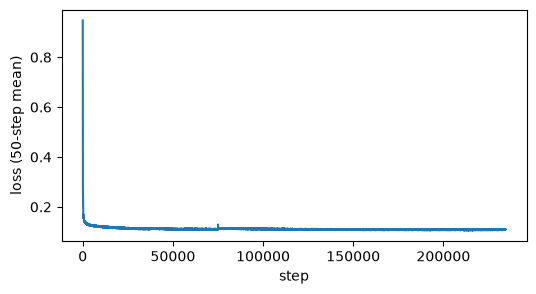

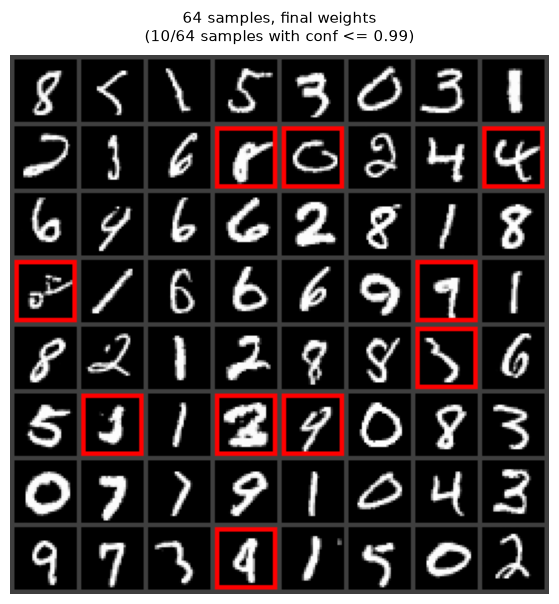

recognition score 89.1%   coverage full
predicted-digit counts [192, 269, 205, 212, 204, 142, 213, 175, 216, 172]   (full coverage needs 140 of each)


In [28]:
resume_trial20(total_epochs=500)

resuming after epoch 500
epoch 501: loss 0.1069  (33 s)
epoch 502: loss 0.1069  (66 s)
epoch 503: loss 0.1073  (98 s)
epoch 504: loss 0.1067  (130 s)
epoch 505: loss 0.1072  (162 s)


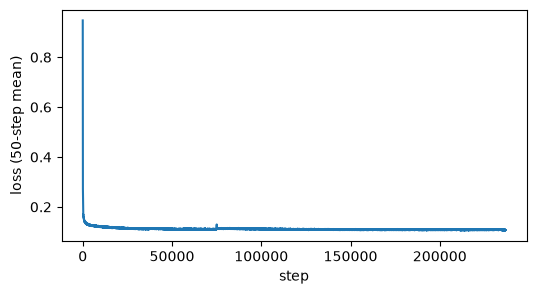

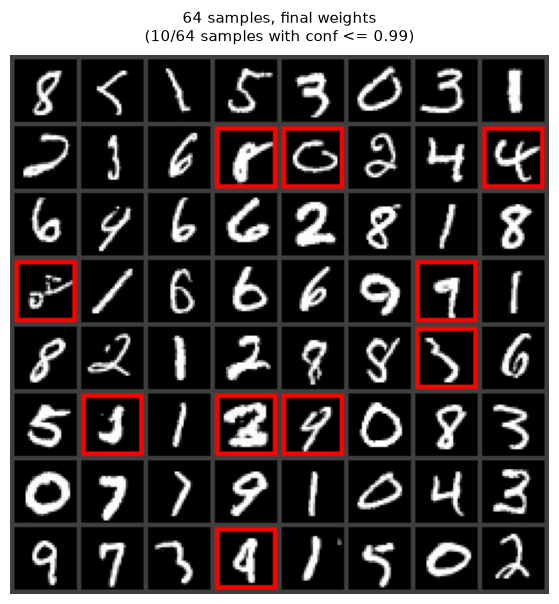

recognition score 89.1%   coverage full
predicted-digit counts [192, 269, 205, 214, 203, 142, 213, 176, 214, 172]   (full coverage needs 140 of each)


In [29]:
resume_trial20(total_epochs=505)

In [40]:
def test_final():
    torch.manual_seed(5561)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.norm = nn.GroupNorm(4, cout)                     # <-- GroupNorm
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.norm(self.c1(x)) + self.t(te)[:, :, None, None]
            change = self.c2(F.silu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=64, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(1, c, tdim)                    # 28 x 28
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 1, 1)

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)

    CKPT = "Report/Results/trial20-checkpoint.pt"
    BATCH, LR = 128, 1e-3

    def load():                                            # <-- a new network and optimizer, then the checkpoint if any
        net = UNet().to(dev)
        opt = torch.optim.Adam(net.parameters(), lr=LR)
        if not os.path.exists(CKPT):
            return net, opt, 0, []
        ck = torch.load(CKPT, map_location=dev)
        net.load_state_dict(ck["net"])
        opt.load_state_dict(ck["opt"])                     # <-- Adam's running averages, not only the weights
        print(f"resuming after epoch {ck['epoch']}")
        return net, opt, ck["epoch"], ck["losses"]


    net, opt, start, losses = load()

    @torch.no_grad()
    def sample(model, x, N=100):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x

    net.eval()
    Z = torch.randn(64, 1, 28, 28, generator=torch.Generator().manual_seed(11)).to(dev)   # fixed noise
    show_grid_highlighted(sample(net, Z), title="64 samples, final weights")

    z = torch.randn(2000, 1, 28, 28, generator=torch.Generator().manual_seed(0)).to(dev)
    u8 = torch.cat([to_uint8(sample(net, z[i:i + 500])) for i in range(0, 2000, 500)])
    np.save(str("Report/Results/trial20-samples.npy"), u8.numpy())

    score, counts, _, _ = recognition(u8)
    full = bool((counts >= 0.07 * len(u8)).all())
    print(f"recognition score {score:.1%}   coverage {'full' if full else 'not full'}")
    print("predicted-digit counts", counts.tolist(), "  (full coverage needs 140 of each)")


resuming after epoch 505


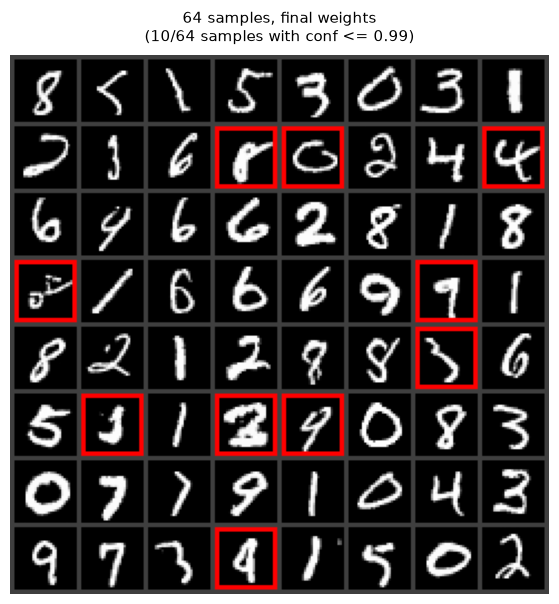

recognition score 89.2%   coverage full
predicted-digit counts [192, 269, 205, 214, 204, 142, 213, 175, 214, 172]   (full coverage needs 140 of each)


In [41]:
test_final()

#### CIFAR-10

In [21]:
cifar = torchvision.datasets.CIFAR10(root="data", train=True, download=True)

100%|██████████| 170M/170M [09:51<00:00, 288kB/s] 


In [22]:
def two_blocks_residual_OT_CLR_GroupNorm_CIFAR10():
    torch.manual_seed(5561)
    X = torch.as_tensor(cifar.data, device=dev).permute(0, 3, 1, 2).float() / 127.5 - 1.0  # (50000, 3, 32, 32)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.norm = nn.GroupNorm(4, cout)                     # <-- GroupNorm
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.norm(self.c1(x)) + self.t(te)[:, :, None, None]
            change = self.c2(F.silu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=64, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(3, c, tdim)             # 32 x 32 (3 RGB channels)
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 3, 1)              # 3 RGB channels

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)


    net = UNet().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    CKPT = str("Report/Results/cifar10-checkpoint.pt")
    def save(net, opt, epoch, losses):                     # <-- everything needed to continue
        ck = {"net": net.state_dict(), "opt": opt.state_dict(), "epoch": epoch, "losses": losses}
        torch.save(ck, CKPT + ".tmp")
        os.replace(CKPT + ".tmp", CKPT)                    # <-- an interrupted save leaves the last checkpoint intact

    EPOCHS, BATCH, LR = 80, 128, 1e-3
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    STEPS, WARMUP = EPOCHS * math.ceil(len(X) / BATCH), 200
    def lr_factor(s):                                      # <-- warm up, then cosine decay to 0
        if s < WARMUP:
            return s / WARMUP
        return 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

    losses, t0 = [], time.time()
    for epoch in range(EPOCHS):
        perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(X), BATCH):
            x1 = X[perm[i:i + BATCH]]                      # data
            x0 = torch.randn_like(x1)                       # noise
            d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
            _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
            x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
            t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
            tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
            xt = (1 - tb) * x0 + tb * x1
            loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            sched.step() 
            losses.append(loss.item())
        save(net, opt, epoch + 1, losses)              # <-- after every epoch
        print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    # plt.figure(figsize=(6, 2.5)); plt.plot([LR * lr_factor(s) for s in range(STEPS)])
    # plt.xlabel("step"); plt.ylabel("learning rate"); plt.show()


    @torch.no_grad()
    def sample(model, x, N=50):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x

    
    net.eval()
    Z = torch.randn(64, 3, 32, 32, generator=torch.Generator().manual_seed(11)).to(dev)
    samples = sample(net, Z)
    
    # Grid display for 3-channel RGB:
    samples_rgb = ((samples + 1.0) * 0.5).clamp(0, 1)
    grid = torchvision.utils.make_grid(samples_rgb, nrow=8, padding=2)
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
    plt.axis("off")
    plt.title("64 CIFAR-10 Generated Samples")
    plt.show()


3,910,851 weights
epoch 1: loss 0.1966  (33 s)
epoch 2: loss 0.1836  (65 s)
epoch 3: loss 0.1811  (97 s)
epoch 4: loss 0.1751  (128 s)
epoch 5: loss 0.1718  (160 s)
epoch 6: loss 0.1703  (194 s)
epoch 7: loss 0.1688  (227 s)
epoch 8: loss 0.1678  (261 s)
epoch 9: loss 0.1663  (293 s)
epoch 10: loss 0.1669  (325 s)
epoch 11: loss 0.1644  (357 s)
epoch 12: loss 0.1666  (389 s)
epoch 13: loss 0.1653  (421 s)
epoch 14: loss 0.1626  (454 s)
epoch 15: loss 0.1645  (486 s)
epoch 16: loss 0.1614  (518 s)
epoch 17: loss 0.1627  (552 s)
epoch 18: loss 0.1641  (584 s)
epoch 19: loss 0.1604  (616 s)
epoch 20: loss 0.1607  (648 s)
epoch 21: loss 0.1598  (682 s)
epoch 22: loss 0.1607  (713 s)
epoch 23: loss 0.1600  (746 s)
epoch 24: loss 0.1582  (778 s)
epoch 25: loss 0.1600  (809 s)
epoch 26: loss 0.1606  (840 s)
epoch 27: loss 0.1610  (872 s)
epoch 28: loss 0.1592  (903 s)
epoch 29: loss 0.1605  (935 s)
epoch 30: loss 0.1575  (967 s)
epoch 31: loss 0.1608  (998 s)
epoch 32: loss 0.1586  (1030 s)
e

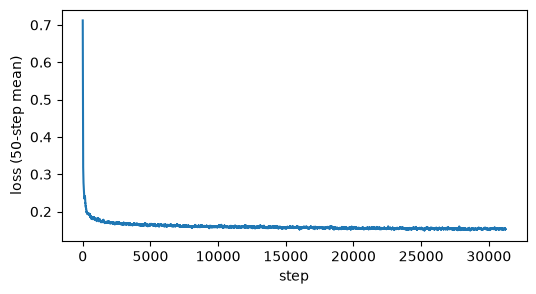

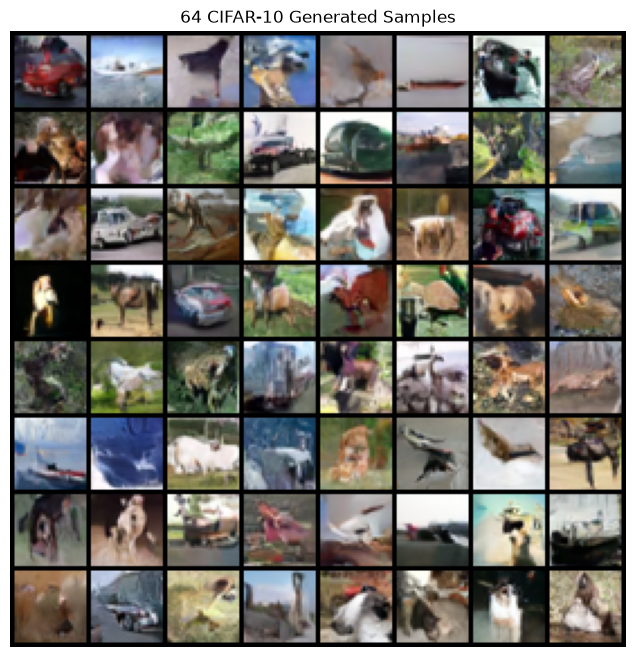

In [23]:
two_blocks_residual_OT_CLR_GroupNorm_CIFAR10()

In [43]:
def resume_cifar10(total_epochs):
    torch.manual_seed(5561)
    X = torch.as_tensor(cifar.data, device=dev).permute(0, 3, 1, 2).float() / 127.5 - 1.0  # (50000, 3, 32, 32)

    class Block(nn.Module):
        # two 3x3 convolutions; t is added after the first
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
            self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
            self.norm = nn.GroupNorm(4, cout)                     # <-- GroupNorm
            self.t = nn.Linear(tdim, cout)                        # one offset per channel
            
            # 1x1 projection if channel dimensions change, otherwise identity
            self.proj = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
            
            # Start with zero change, so the block initially returns its input (or projected input)
            nn.init.zeros_(self.c2.weight)
            nn.init.zeros_(self.c2.bias)
            
        def forward(self, x, te):
            h = self.norm(self.c1(x)) + self.t(te)[:, :, None, None]
            change = self.c2(F.silu(h))
            return self.proj(x) + change


    class Level(nn.Module):
        # <-- two blocks in a row; the first changes the channel count
        def __init__(self, cin, cout, tdim):
            super().__init__()
            self.b1, self.b2 = Block(cin, cout, tdim), Block(cout, cout, tdim)

        def forward(self, x, te):
            return self.b2(self.b1(x, te), te)


    class UNet(nn.Module):
        def __init__(self, width=64, tdim=32):
            super().__init__()
            c = width
            self.register_buffer("freq", torch.exp(torch.linspace(0, math.log(1000), tdim // 2)))
            self.temb = nn.Sequential(nn.Linear(tdim, tdim), nn.SiLU(), nn.Linear(tdim, tdim))

            self.down1 = Level(3, c, tdim)             # 32 x 32 (3 RGB channels)
            self.down2 = Level(c, 2 * c, tdim)                # 14 x 14
            self.mid = Level(2 * c, 4 * c, tdim)              # 7 x 7
            self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2)
            self.dec2 = Level(4 * c, 2 * c, tdim)
            self.up1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2)
            self.dec1 = Level(2 * c, c, tdim)
            self.out = nn.Conv2d(c, 3, 1)              # 3 RGB channels

        def forward(self, x, t):                              # x: B x 1 x 28 x 28, t: B x 1
            a = t * self.freq
            te = self.temb(torch.cat([a.sin(), a.cos()], 1))  # t embedded once, used by every block
            s1 = self.down1(x, te)
            s2 = self.down2(F.max_pool2d(s1, 2), te)
            m = self.mid(F.max_pool2d(s2, 2), te)
            h = self.dec2(torch.cat([self.up2(m), s2], 1), te)
            h = self.dec1(torch.cat([self.up1(h), s1], 1), te)
            return self.out(h)

    CKPT = "Report/Results/cifar10-checkpoint.pt"
    BATCH, LR = 128, 1e-3

    def save(net, opt, epoch, losses):                     # <-- everything needed to continue
        ck = {"net": net.state_dict(), "opt": opt.state_dict(), "epoch": epoch, "losses": losses}
        torch.save(ck, CKPT + ".tmp")
        os.replace(CKPT + ".tmp", CKPT)                    # <-- an interrupted save leaves the last checkpoint intact

    def load():                                            # <-- a new network and optimizer, then the checkpoint if any
        net = UNet().to(dev)
        opt = torch.optim.Adam(net.parameters(), lr=LR)
        if not os.path.exists(CKPT):
            return net, opt, 0, []
        ck = torch.load(CKPT, map_location=dev)
        net.load_state_dict(ck["net"])
        opt.load_state_dict(ck["opt"])                     # <-- Adam's running averages, not only the weights
        print(f"resuming after epoch {ck['epoch']}")
        return net, opt, ck["epoch"], ck["losses"]

    def train_until(last_epoch):
        net, opt, start, losses = load()

        STEPS = total_epochs * math.ceil(len(X) / BATCH)
        WARMUP = 200
        def lr_factor(s):
            if s < WARMUP:
                return s / WARMUP
            return 0.5 * (1 + math.cos(math.pi * (s - WARMUP) / (STEPS - WARMUP)))
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)

        steps_done = start * math.ceil(len(X) / BATCH)
        for _ in range(steps_done):
            sched.step()

        t0 = time.time()
        for epoch in range(start, last_epoch):              # <-- Corrected range
            perm = torch.randperm(len(X), device=dev)
            for i in range(0, len(X), BATCH):
                x1 = X[perm[i:i + BATCH]]                      # data
                x0 = torch.randn_like(x1)                       # noise
                d2 = torch.cdist(x1.flatten(1), x0.flatten(1)) ** 2       # <-- B x B squared distances
                _, j = linear_sum_assignment(d2.cpu().numpy())            # <-- least total distance
                x0 = x0[torch.as_tensor(j, device=dev)]                   # <-- image k is paired with noise j[k]
                t = torch.rand(len(x1), 1, device=dev)          # t ~ U[0, 1]
                tb = t[:, :, None, None]                        # one t per image: B x 1 x 1 x 1
                xt = (1 - tb) * x0 + tb * x1
                loss = ((net(xt, t) - (x1 - x0)) ** 2).mean()
                opt.zero_grad(); loss.backward(); opt.step()
                sched.step() 
                losses.append(loss.item())
            save(net, opt, epoch + 1, losses)              # <-- after every epoch
            print(f"epoch {epoch + 1}: loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")
        return net, losses                                 # <-- Return added

    net, losses = train_until(total_epochs)

    plt.figure(figsize=(6, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
    plt.xlabel("step"); plt.ylabel("loss (50-step mean)"); plt.show()

    @torch.no_grad()
    def sample(model, x, N=50):
        # <-- Heun: an Euler step to guess the end, then step again with the average of
        # the velocities at both ends. Two network calls per step; the last step is plain Euler.
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            v = model(x, t)
            if i < N - 1:
                v2 = model(x + v / N, t + 1 / N)
                v = (v + v2) / 2
            x = x + v / N
        return x

    
    net.eval()
    Z = torch.randn(64, 3, 32, 32, generator=torch.Generator().manual_seed(11)).to(dev)
    samples = sample(net, Z)
    
    # Grid display for 3-channel RGB:
    samples_rgb = ((samples + 1.0) * 0.5).clamp(0, 1)
    grid = torchvision.utils.make_grid(samples_rgb, nrow=8, padding=2)
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
    plt.axis("off")
    plt.title("64 CIFAR-10 Generated Samples")
    plt.show()


resuming after epoch 80


c:\Users\yashp\miniconda3\envs\flow_matching\Lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


epoch 81: loss 0.1543  (35 s)
epoch 82: loss 0.1550  (70 s)
epoch 83: loss 0.1574  (103 s)
epoch 84: loss 0.1568  (137 s)
epoch 85: loss 0.1552  (170 s)
epoch 86: loss 0.1551  (203 s)
epoch 87: loss 0.1551  (238 s)
epoch 88: loss 0.1551  (271 s)
epoch 89: loss 0.1545  (305 s)
epoch 90: loss 0.1558  (338 s)
epoch 91: loss 0.1538  (371 s)
epoch 92: loss 0.1560  (405 s)
epoch 93: loss 0.1550  (439 s)
epoch 94: loss 0.1531  (475 s)
epoch 95: loss 0.1552  (509 s)
epoch 96: loss 0.1527  (542 s)
epoch 97: loss 0.1543  (576 s)
epoch 98: loss 0.1559  (610 s)
epoch 99: loss 0.1525  (643 s)
epoch 100: loss 0.1531  (677 s)
epoch 101: loss 0.1525  (711 s)
epoch 102: loss 0.1535  (744 s)
epoch 103: loss 0.1530  (778 s)
epoch 104: loss 0.1512  (812 s)
epoch 105: loss 0.1535  (846 s)
epoch 106: loss 0.1540  (880 s)
epoch 107: loss 0.1545  (914 s)
epoch 108: loss 0.1530  (948 s)
epoch 109: loss 0.1545  (982 s)
epoch 110: loss 0.1517  (1017 s)
epoch 111: loss 0.1551  (1051 s)
epoch 112: loss 0.1532  (10

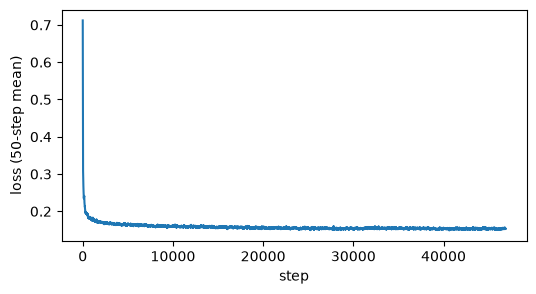

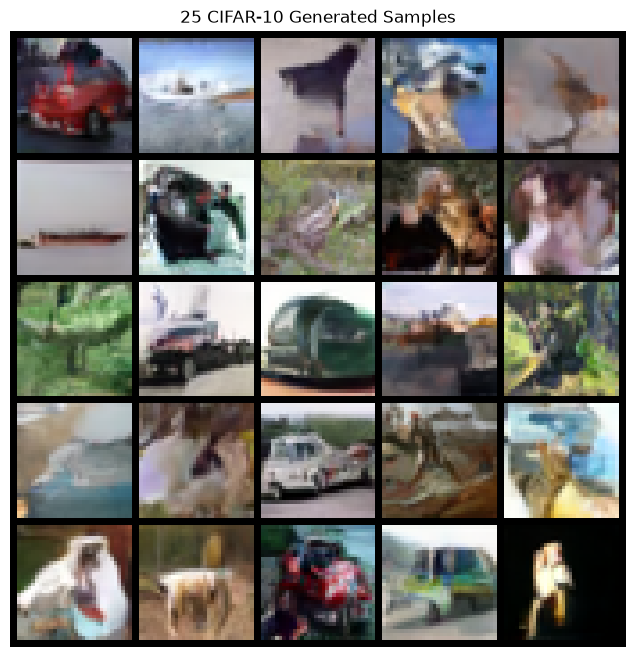

In [31]:
resume_cifar10(total_epochs=120)

resuming after epoch 120
epoch 121: loss 0.1532  (33 s)
epoch 122: loss 0.1538  (67 s)
epoch 123: loss 0.1562  (100 s)
epoch 124: loss 0.1557  (134 s)
epoch 125: loss 0.1541  (167 s)
epoch 126: loss 0.1541  (201 s)
epoch 127: loss 0.1541  (235 s)
epoch 128: loss 0.1542  (269 s)
epoch 129: loss 0.1536  (302 s)
epoch 130: loss 0.1550  (336 s)
epoch 131: loss 0.1530  (369 s)
epoch 132: loss 0.1552  (403 s)
epoch 133: loss 0.1543  (436 s)
epoch 134: loss 0.1524  (470 s)
epoch 135: loss 0.1546  (503 s)
epoch 136: loss 0.1521  (537 s)
epoch 137: loss 0.1536  (571 s)
epoch 138: loss 0.1553  (604 s)
epoch 139: loss 0.1519  (638 s)
epoch 140: loss 0.1526  (671 s)
epoch 141: loss 0.1520  (705 s)
epoch 142: loss 0.1530  (739 s)
epoch 143: loss 0.1525  (772 s)
epoch 144: loss 0.1508  (806 s)
epoch 145: loss 0.1531  (839 s)
epoch 146: loss 0.1537  (873 s)
epoch 147: loss 0.1541  (907 s)
epoch 148: loss 0.1527  (942 s)
epoch 149: loss 0.1542  (975 s)
epoch 150: loss 0.1514  (1009 s)
epoch 151: loss 

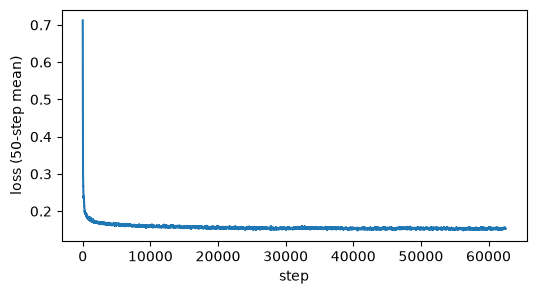

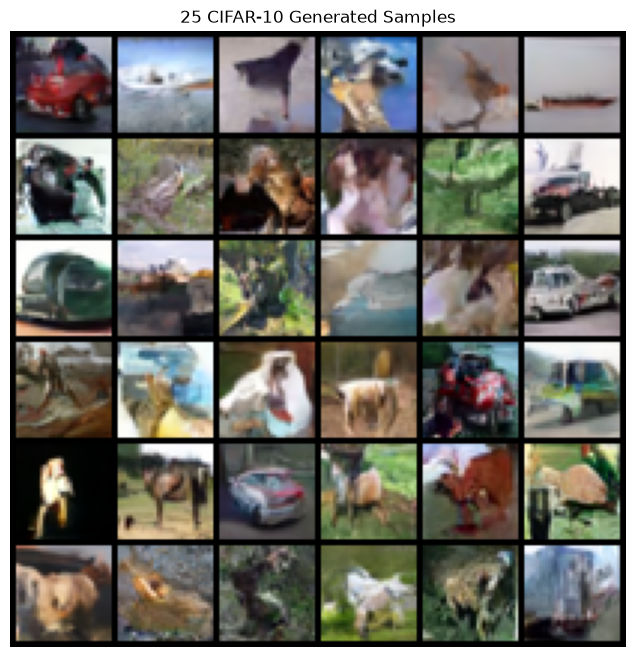

In [34]:
resume_cifar10(total_epochs=160)

resuming after epoch 160


c:\Users\yashp\miniconda3\envs\flow_matching\Lib\site-packages\torch\optim\lr_scheduler.py:227: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


epoch 161: loss 0.1525  (36 s)
epoch 162: loss 0.1532  (73 s)
epoch 163: loss 0.1556  (109 s)
epoch 164: loss 0.1551  (146 s)
epoch 165: loss 0.1536  (182 s)
epoch 166: loss 0.1535  (219 s)
epoch 167: loss 0.1536  (255 s)
epoch 168: loss 0.1537  (292 s)
epoch 169: loss 0.1532  (328 s)
epoch 170: loss 0.1545  (365 s)
epoch 171: loss 0.1525  (401 s)
epoch 172: loss 0.1548  (438 s)
epoch 173: loss 0.1539  (474 s)
epoch 174: loss 0.1520  (511 s)
epoch 175: loss 0.1542  (548 s)
epoch 176: loss 0.1517  (584 s)
epoch 177: loss 0.1533  (621 s)
epoch 178: loss 0.1549  (657 s)
epoch 179: loss 0.1516  (694 s)
epoch 180: loss 0.1524  (730 s)
epoch 181: loss 0.1517  (767 s)
epoch 182: loss 0.1528  (804 s)
epoch 183: loss 0.1523  (840 s)
epoch 184: loss 0.1505  (877 s)
epoch 185: loss 0.1529  (913 s)
epoch 186: loss 0.1535  (950 s)
epoch 187: loss 0.1539  (986 s)
epoch 188: loss 0.1525  (1023 s)
epoch 189: loss 0.1541  (1060 s)
epoch 190: loss 0.1513  (1096 s)
epoch 191: loss 0.1547  (1133 s)
epoch 

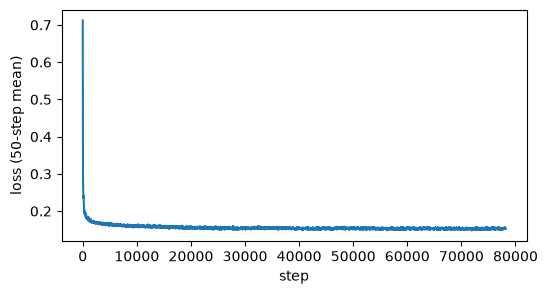

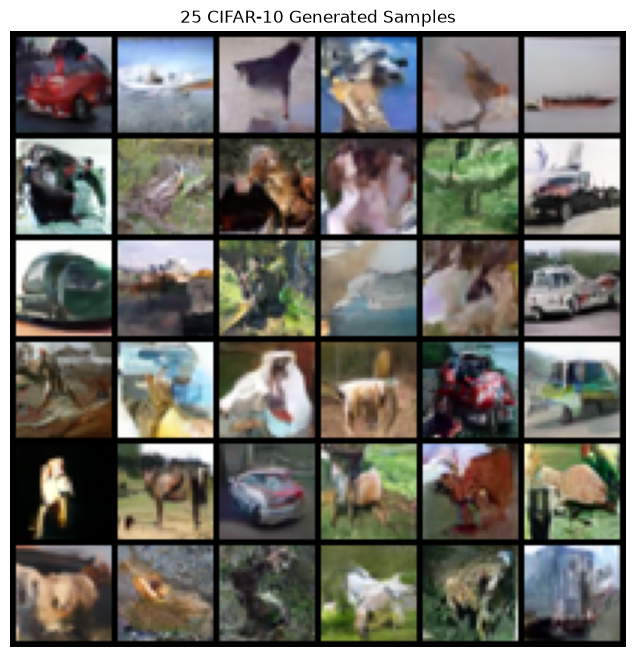

In [42]:
resume_cifar10(total_epochs=200)

resuming after epoch 200
epoch 201: loss 0.1523  (33 s)
epoch 202: loss 0.1529  (66 s)
epoch 203: loss 0.1554  (100 s)
epoch 204: loss 0.1549  (133 s)
epoch 205: loss 0.1534  (167 s)
epoch 206: loss 0.1534  (200 s)
epoch 207: loss 0.1534  (233 s)
epoch 208: loss 0.1535  (267 s)
epoch 209: loss 0.1530  (301 s)
epoch 210: loss 0.1544  (335 s)
epoch 211: loss 0.1524  (369 s)
epoch 212: loss 0.1547  (402 s)
epoch 213: loss 0.1538  (436 s)
epoch 214: loss 0.1520  (470 s)
epoch 215: loss 0.1541  (503 s)
epoch 216: loss 0.1516  (537 s)
epoch 217: loss 0.1532  (571 s)
epoch 218: loss 0.1549  (604 s)
epoch 219: loss 0.1516  (638 s)
epoch 220: loss 0.1523  (671 s)
epoch 221: loss 0.1517  (705 s)
epoch 222: loss 0.1527  (738 s)
epoch 223: loss 0.1523  (772 s)
epoch 224: loss 0.1505  (806 s)
epoch 225: loss 0.1528  (839 s)
epoch 226: loss 0.1534  (872 s)
epoch 227: loss 0.1539  (906 s)
epoch 228: loss 0.1525  (939 s)
epoch 229: loss 0.1540  (973 s)
epoch 230: loss 0.1512  (1006 s)
epoch 231: loss 

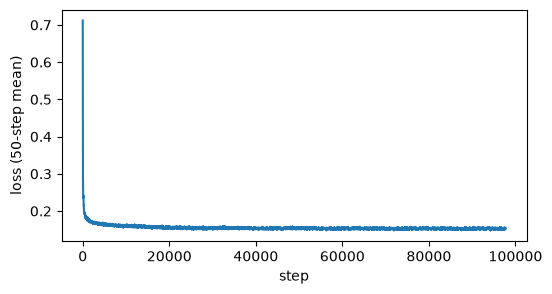

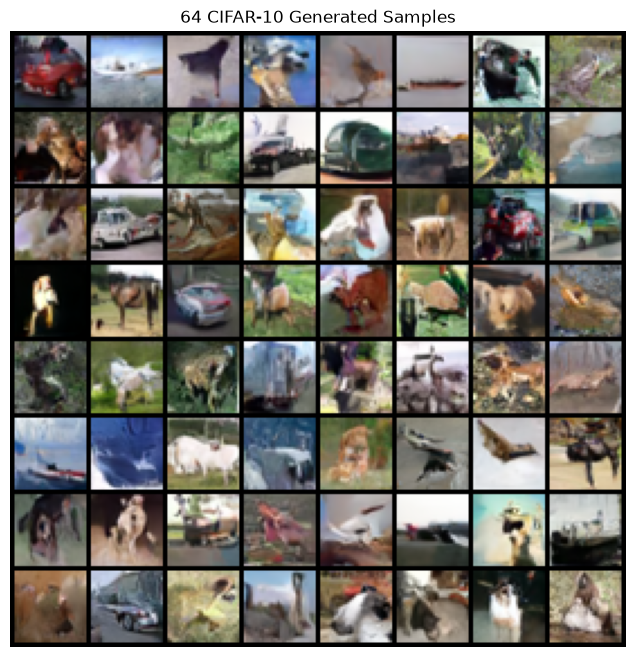

In [44]:
resume_cifar10(total_epochs=250)

resuming after epoch 250
epoch 251: loss 0.1519  (34 s)
epoch 252: loss 0.1525  (67 s)
epoch 253: loss 0.1550  (101 s)
epoch 254: loss 0.1545  (134 s)
epoch 255: loss 0.1530  (168 s)
epoch 256: loss 0.1530  (202 s)
epoch 257: loss 0.1531  (235 s)
epoch 258: loss 0.1532  (269 s)
epoch 259: loss 0.1527  (303 s)
epoch 260: loss 0.1540  (336 s)
epoch 261: loss 0.1521  (370 s)
epoch 262: loss 0.1544  (404 s)
epoch 263: loss 0.1535  (438 s)
epoch 264: loss 0.1517  (472 s)
epoch 265: loss 0.1538  (506 s)
epoch 266: loss 0.1514  (540 s)
epoch 267: loss 0.1530  (574 s)
epoch 268: loss 0.1546  (608 s)
epoch 269: loss 0.1513  (642 s)
epoch 270: loss 0.1521  (675 s)
epoch 271: loss 0.1514  (710 s)
epoch 272: loss 0.1525  (744 s)
epoch 273: loss 0.1520  (778 s)
epoch 274: loss 0.1503  (812 s)
epoch 275: loss 0.1526  (846 s)
epoch 276: loss 0.1532  (882 s)
epoch 277: loss 0.1537  (916 s)
epoch 278: loss 0.1523  (951 s)
epoch 279: loss 0.1539  (987 s)
epoch 280: loss 0.1510  (1022 s)
epoch 281: loss 

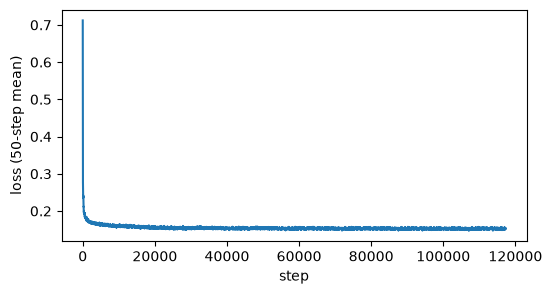

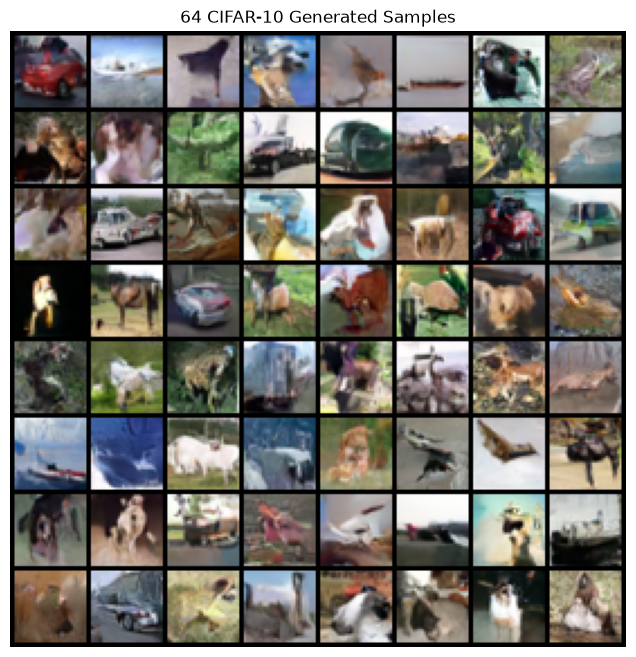

In [45]:
resume_cifar10(total_epochs=300)